# Tail-risk study: scale-equivariant early magnitude distributions

This notebook explains every approach compared in `tailrisk/` and shows the saved
out-of-fold results. Nothing here retrains a model. The protocol and arm definitions are in
`tailrisk/README.md`. The narrative conclusions (positive and negative) are in
`tailrisk/FINDINGS.md`, reproduced at the end.

**Question.** From the first 1, 3 or 5 s after the P arrival at one station, can we reduce
the error on rare large earthquakes (M≥4, M≥5) *without* increasing the error on the bulk
of ordinary records?

**Key protocol choices**
1. *Leave-sequence-out CV.* All 1,159,249 INSTANCE records are split by Gardner–Knopoff
   aftershock sequences into 5 folds. The tail then has 346 M≥4 and 31 M≥5 events, instead of
   the 13 / 1 of the 2018 VAL split.
2. *Same trunk for every arm.* Only the predictive head / loss changes.
3. *Frontier evaluation.* For a posterior p, the rule "multiply the tail mass by r and take
   the median" is the Bayes action for the loss r·|e| on M≥4 and |e| otherwise. Sweeping r
   traces the best bulk/tail trade-off that p allows. We compare arms at *matched bulk MAE*.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
EVAL = 'results/eval_final_all.json'
rep = json.load(open(EVAL))
print('records:', rep['n_records'], ' M>=4 events:', rep['n_M4_events'])

records: 1159249  M>=4 events: 346


## 1. Point metrics of the fixed actions

`mean` is the posterior-mean action; `med` is the posterior median (r = 1). M≥4 MAE is
record-weighted; M≥4 eventMAE gives every M≥4 earthquake equal weight. CVaR95 is the mean of
the worst 5% of absolute errors over *all* records (the "largest errors" sense of long tail).

In [2]:
rows = []
for arm, by_d in rep['arms'].items():
    for d, r in by_d.items():
        for act in ('mean_action', 'median_action'):
            m = r[act]
            rows.append({'arm': arm, 'deadline': d, 'action': act.split('_')[0], **{k: round(m[k], 4) for k in
                         ('MAE', 'MedAE', 'CVaR95', 'M>=4_MAE', 'M>=4_eventMAE', 'M>=5_MAE', 'M>=4_bias', 'FP4_rate')}})
pd.set_option('display.width', 200)
pd.DataFrame(rows).set_index(['deadline', 'action', 'arm']).sort_index()

MAE   MedAE  CVaR95  M>=4_MAE  M>=4_eventMAE  M>=5_MAE  M>=4_bias  FP4_rate
deadline action arm                                                                                      
1s       mean   cat_aug    0.3377  0.2617  1.1939    0.7256         0.7345    1.0285    -0.6596    0.0008
                cat_ce     0.3291  0.2497  1.1860    0.7684         0.7749    1.1007    -0.7193    0.0007
                cat_hubce  0.3374  0.2541  1.2257    0.6346         0.6384    0.9229    -0.5124    0.0041
                cat_lds    0.3572  0.2777  1.2494    0.6304         0.6358    0.9041    -0.5133    0.0028
                eqgr_nll   0.3299  0.2504  1.1869    0.7298         0.7466    1.0037    -0.6535    0.0008
                mix_nll    0.3300  0.2508  1.1865    0.7555         0.7659    1.0645    -0.7018    0.0006
                mixgr_nll  0.3288  0.2495  1.1821    0.7405         0.7515    1.0430    -0.6837    0.0006
         median cat_aug    0.3374  0.2596  1.2121    0.7371         0.7464    1.0363    -0.6741    0.0008
                cat_ce     0.3272  0.2398  1.2148    0.7814         0.7879    1.1100    -0.7327    0.0008
                cat_hubce  0.3335  0.2435  1.2403    0.6992         0.7006    0.9951    -0.6069    0.0026
                cat_lds    0.3554  0.2676  1.2907    0.6379         0.6425    0.8902    -0.4997    0.0035
                eqgr_nll   0.3277  0.2402  1.2136    0.7421         0.7608    1.0122    -0.6672    0.0008
                mix_nll    0.3277  0.2405  1.2134    0.7637         0.7753    1.0510    -0.7077    0.0006
                mixgr_nll  0.3267  0.2396  1.2086    0.7493         0.7621    1.0227    -0.6882    0.0007
3s       mean   cat_aug    0.2797  0.2122  1.0347    0.5560         0.5705    0.7660    -0.4830    0.0006
                cat_ce     0.2728  0.2023  1.0306    0.5927         0.6054    0.8352    -0.5389    0.0005
                cat_hubce  0.2800  0.2074  1.0574    0.4825         0.4925    0.6711    -0.3643    0.0027
                cat_lds    0.2943  0.2227  1.0752    0.4933         0.5030    0.6604    -0.3826    0.0018
                eqgr_nll   0.2707  0.2000  1.0292    0.5492         0.5716    0.6309    -0.4546    0.0006
                mix_nll    0.2723  0.2019  1.0295    0.5717         0.5880    0.7824    -0.5122    0.0005
                mixgr_nll  0.2695  0.1990  1.0232    0.5582         0.5757    0.7399    -0.4951    0.0005
         median cat_aug    0.2796  0.2109  1.0498    0.5685         0.5833    0.7818    -0.5018    0.0006
                cat_ce     0.2714  0.1957  1.0577    0.6101         0.6231    0.8604    -0.5574    0.0006
                cat_hubce  0.2775  0.2005  1.0726    0.5470         0.5546    0.7270    -0.4573    0.0015
                cat_lds    0.2924  0.2149  1.1091    0.5034         0.5124    0.6605    -0.3750    0.0021
                eqgr_nll   0.2691  0.1929  1.0587    0.5600         0.5836    0.6383    -0.4691    0.0006
                mix_nll    0.2704  0.1948  1.0566    0.5768         0.5941    0.7648    -0.5161    0.0005
                mixgr_nll  0.2679  0.1921  1.0514    0.5646         0.5834    0.7165    -0.4983    0.0005
5s       mean   cat_aug    0.2466  0.1817  0.9714    0.5090         0.5235    0.7142    -0.4316    0.0005
                cat_ce     0.2409  0.1741  0.9655    0.5472         0.5594    0.7842    -0.4896    0.0004
                cat_hubce  0.2481  0.1801  0.9869    0.4407         0.4529    0.6229    -0.3272    0.0022
                cat_lds    0.2592  0.1903  1.0048    0.4622         0.4734    0.6287    -0.3536    0.0015
                eqgr_nll   0.2367  0.1699  0.9610    0.4939         0.5176    0.5384    -0.3962    0.0005
                mix_nll    0.2399  0.1731  0.9649    0.5255         0.5426    0.7208    -0.4656    0.0004
                mixgr_nll  0.2367  0.1703  0.9546    0.5101         0.5281    0.6747    -0.4440    0.0004
         median cat_aug    0.2467  0.1814  0.9853    0.5227         0.5377    0.7340    -0.4530    0.0005
  

## 2. Bulk-constrained comparisons against the reference arm

For each bootstrap replicate (whole sequences resampled), each arm picks the tail weight r
that minimizes its tail error subject to bulk MAE ≤ the reference arm's median-action bulk MAE
(`bulkcap0_*`), or ≤ that value × 1.002 (`bulkcap0.002_*`). The table shows arm minus
reference; negative means the arm achieves a lower tail error without spending more bulk
error. Brackets are 95% intervals. `tailcap_MAE` is the reverse comparison: the least bulk
MAE subject to M≥4 MAE ≤ the reference's. `median`/`mean` rows compare the fixed actions.

In [3]:
rows = []
for arm, by_d in rep.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key in ('bulkcap0_M>=4_MAE', 'bulkcap0_M>=4_eventMAE', 'bulkcap0_M>=5_MAE', 'bulkcap0.002_M>=4_MAE', 'tailcap_MAE'):
            v = c.get(key)
            if v:
                rows.append({'arm': arm, 'deadline': d, 'comparison': key, 'delta': round(v['mean'], 4),
                             'lo95': round(v['lo'], 4), 'hi95': round(v['hi'], 4), 'P(arm better)': round(v['p_arm_better'], 3)})
        for act in ('median', 'mean'):
            for key, v in c[act].items():
                if v:
                    rows.append({'arm': arm, 'deadline': d, 'comparison': f'{act} action {key}', 'delta': round(v['mean'], 4),
                                 'lo95': round(v['lo'], 4), 'hi95': round(v['hi'], 4), 'P(arm better)': round(v['p_arm_better'], 3)})
pd.DataFrame(rows).set_index(['comparison', 'deadline', 'arm']).sort_index()

delta    lo95    hi95  P(arm better)
comparison            deadline arm                                             
bulkcap0.002_M>=4_MAE 1s       cat_ce     0.0007 -0.0395  0.0700          0.597
                               eqgr_nll  -0.0077 -0.0511  0.0409          0.625
                               mixgr_nll -0.0448 -0.0640 -0.0290          1.000
                      3s       cat_ce     0.0797  0.0626  0.0912          0.000
                               eqgr_nll  -0.0457 -0.0713 -0.0252          1.000
...                                          ...     ...     ...            ...
tailcap_MAE           5s       cat_ce     0.0020  0.0015  0.0029          0.000
                               cat_hubce  0.0078  0.0065  0.0089          0.000
                               cat_lds    0.0178  0.0166  0.0196          0.000
                               eqgr_nll  -0.0033 -0.0039 -0.0029          1.000
                               mixgr_nll -0.0032 -0.0035 -0.0027          1.000

[191 rows x 4 columns]

## 3. Frontiers

Each curve is one arm's posterior evaluated over r. Lower-left is better. ● marks the median action, □ the mean action.

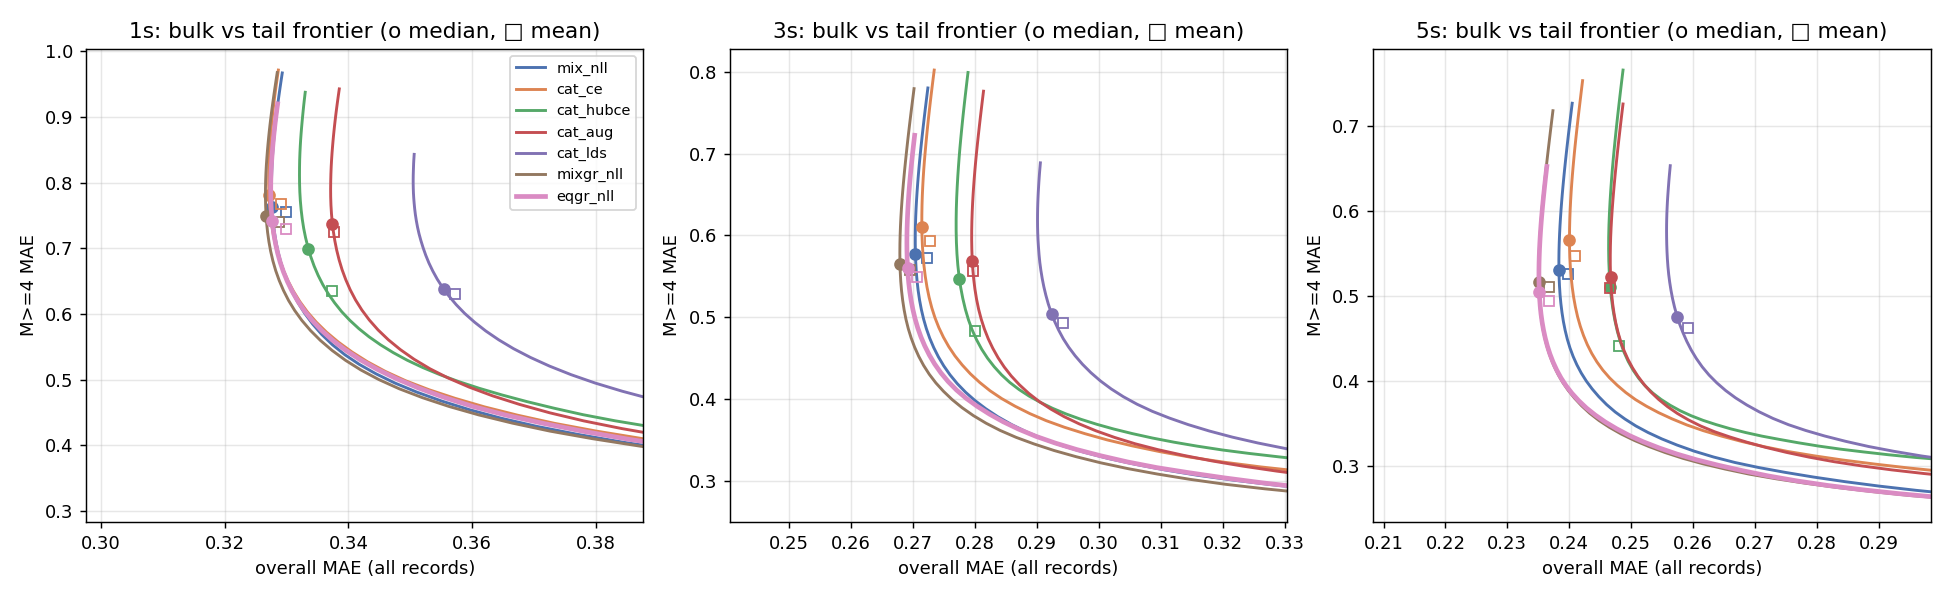

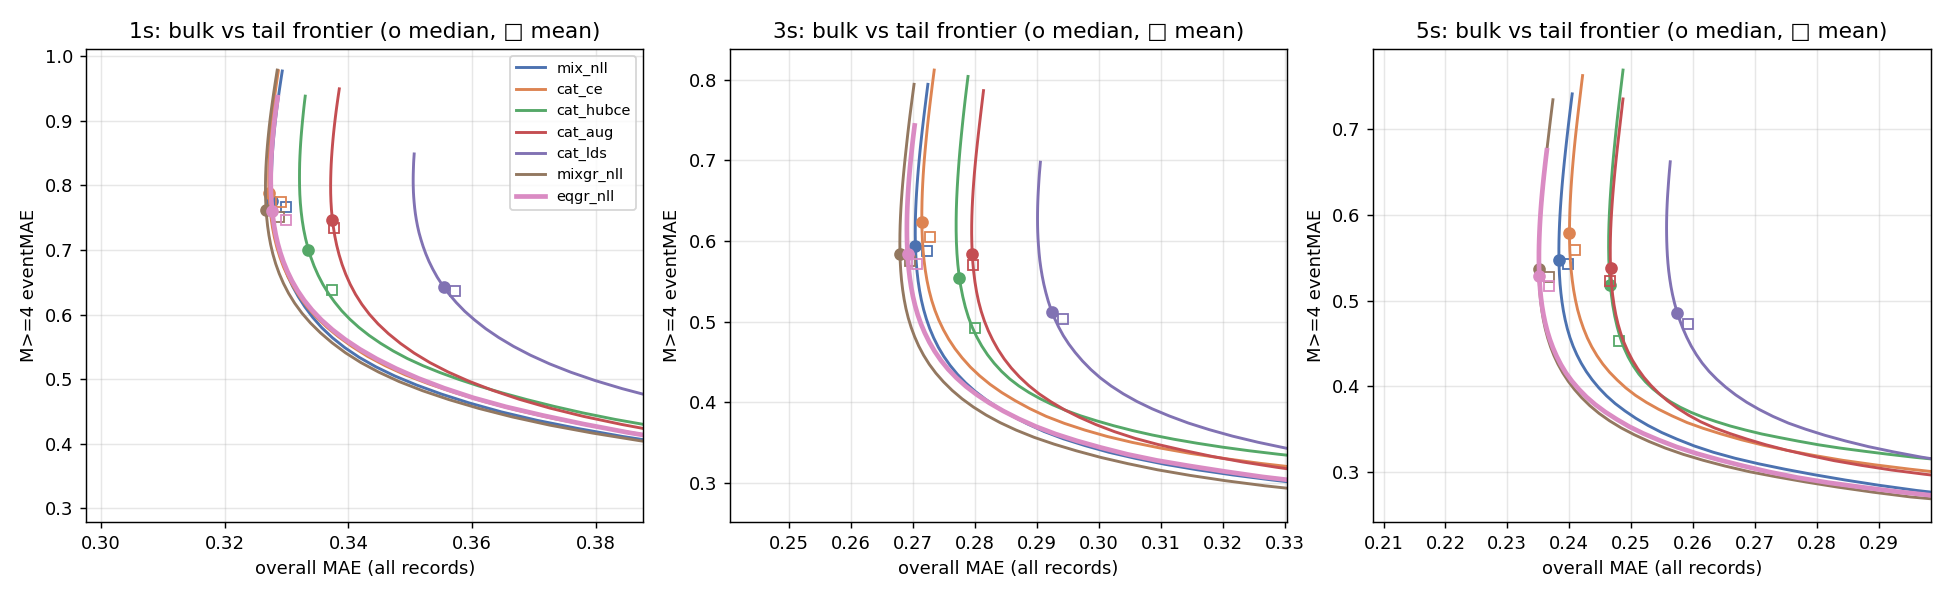

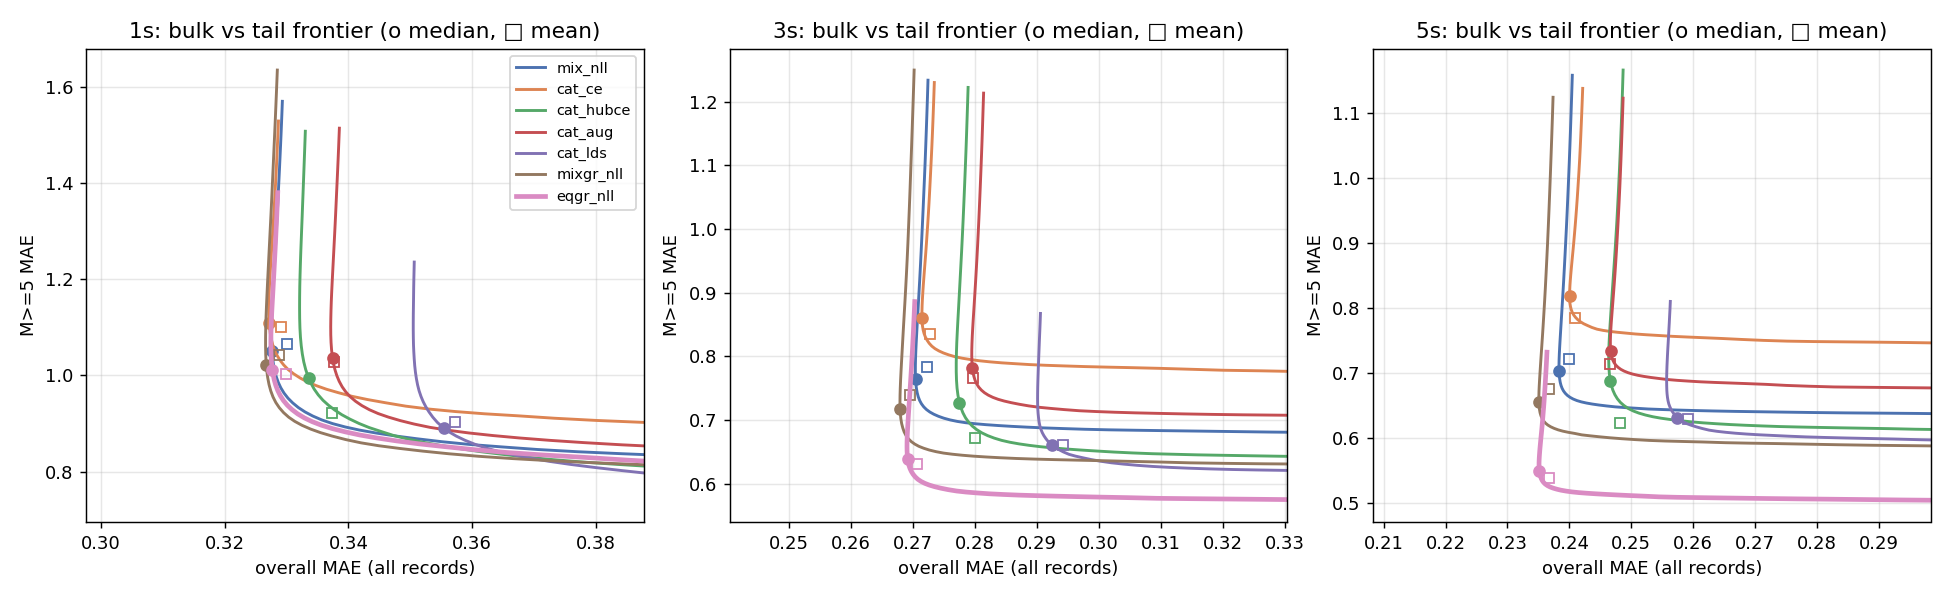

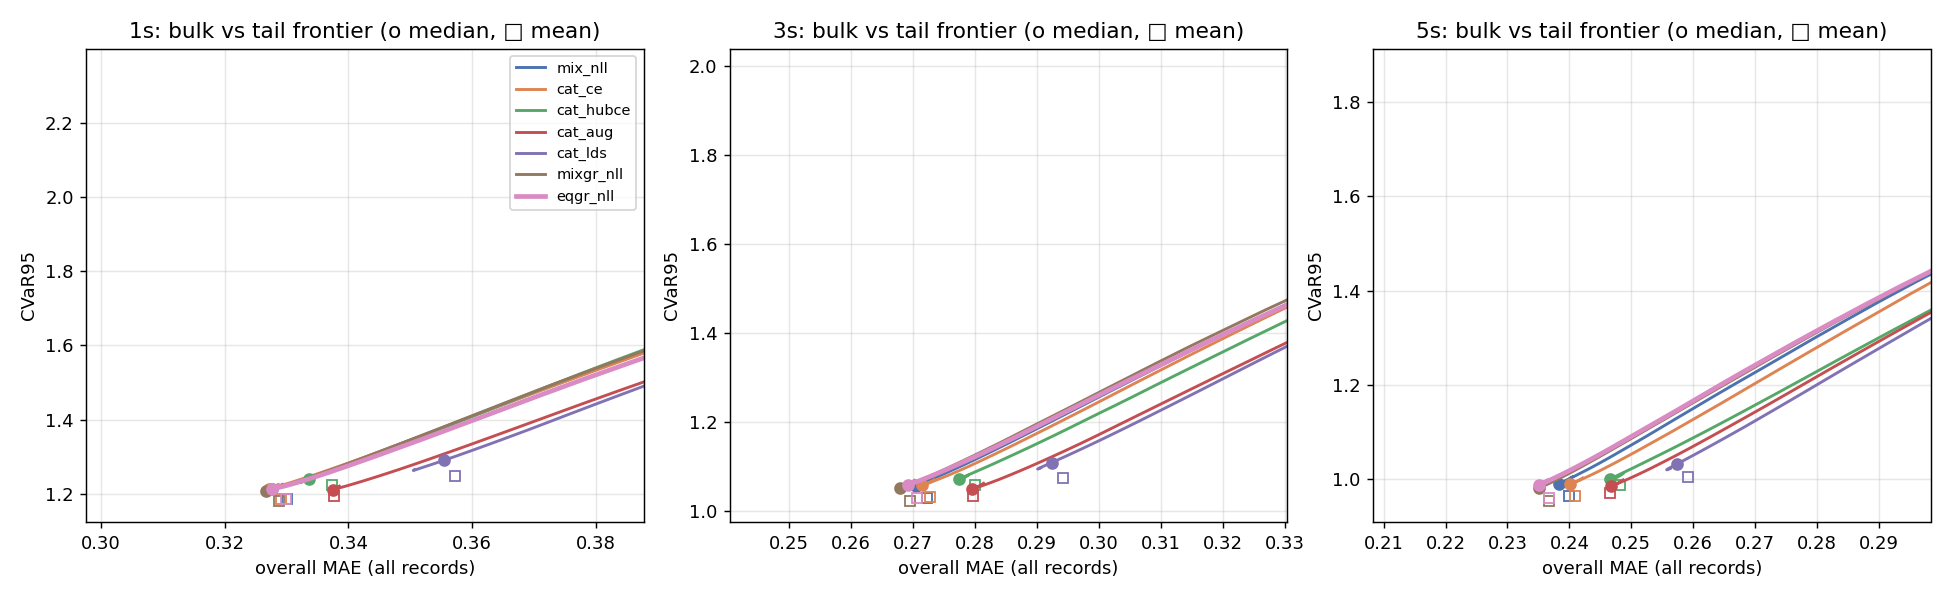

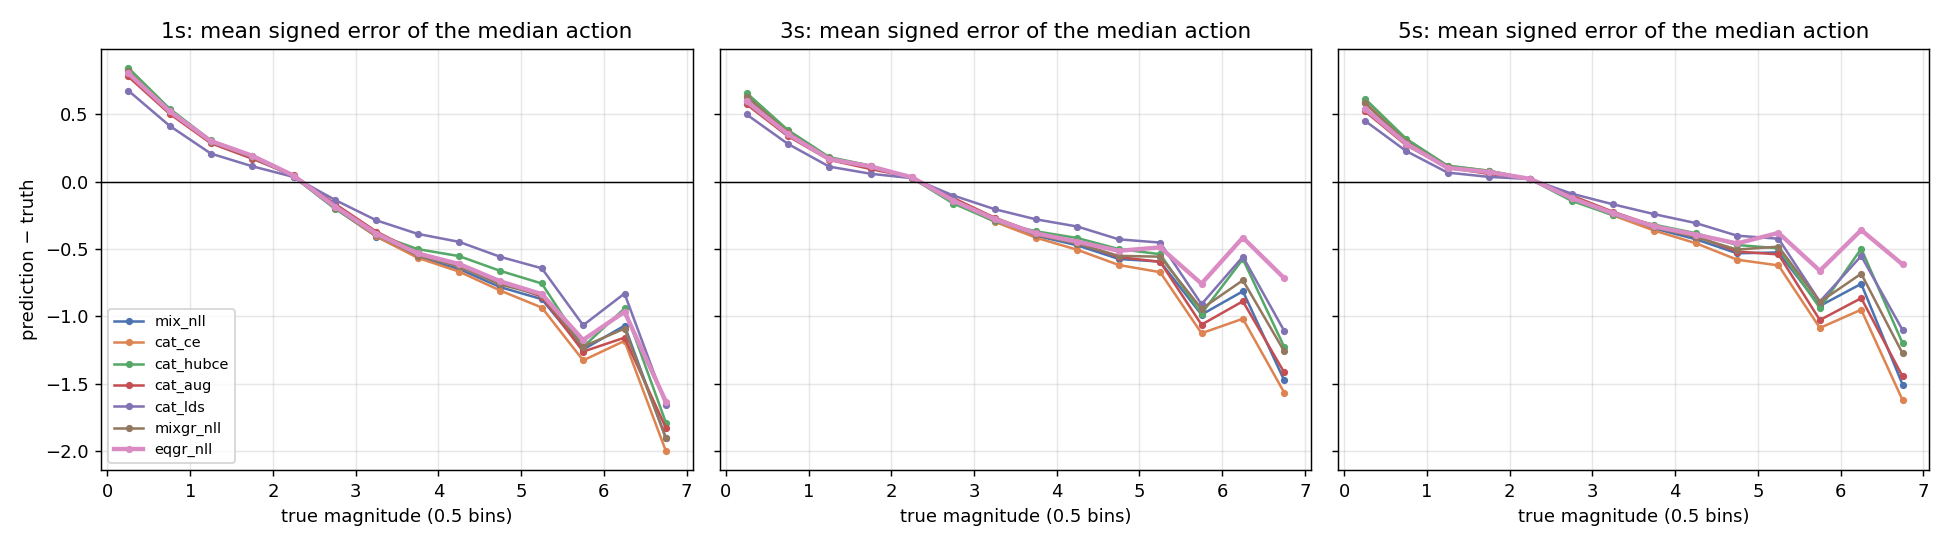

In [4]:
for f in ('frontier_Mge4MAE.png', 'frontier_Mge4eventMAE.png', 'frontier_Mge5MAE.png', 'frontier_CVaR95.png', 'bias_by_magnitude.png'):
    display(Image(filename='figures/' + f))

## 4. Mechanism: does the prediction respond to amplitude?

We multiply the held-out ground motion by 10^δ and record the change in the predicted
median. For an amplitude-defined magnitude the change should be close to δ. A model that
saturates in the sparse upper tail moves much less. The equivariant head moves exactly
κ(s)·δ by construction; the free heads have to learn this response from data.

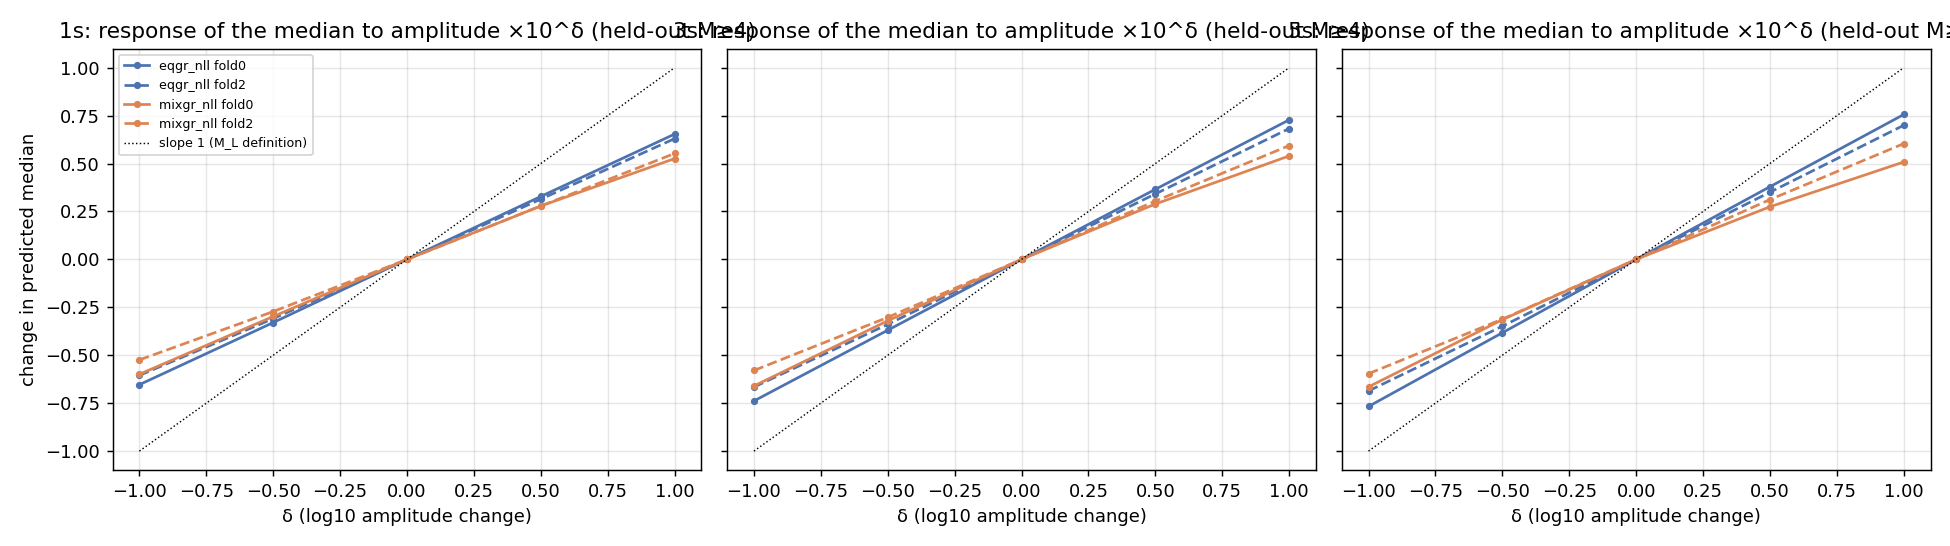

eqgr_nll fold0 {'1s': 0.654, '3s': 0.728, '5s': 0.756}
eqgr_nll fold2 {'1s': 0.63, '3s': 0.682, '5s': 0.7}
mixgr_nll fold0 {'1s': 0.526, '3s': 0.54, '5s': 0.508}
mixgr_nll fold2 {'1s': 0.553, '3s': 0.594, '5s': 0.604}


In [5]:
display(Image(filename='figures/amplitude_response.png'))
diag = json.load(open('results/diagnostics_eqgr_nll_mixgr_nll.json'))
for arm, d in diag.items():
    for f, g in d['amplitude_response'].items():
        print(arm, f, {k: round(v['slope_up'], 3) for k, v in g['M>=4'].items()})

## 5. Classical feature + gradient-boosting baseline (E3WS-style)

In [6]:
gbm = json.load(open('results/gbm_e3ws_summary.json'))
pd.DataFrame({d: {k: round(v[k], 4) for k in ('MAE', 'MedAE', 'CVaR95', 'M>=4_MAE', 'M>=4_eventMAE', 'M>=5_MAE')} for d, v in gbm.items()})

,1s,3s,5s
MAE,0.3587,0.3298,0.3100
MedAE,0.2716,0.2475,0.2290
CVaR95,1.2651,1.1866,1.1496
M>=4_MAE,0.8747,0.7682,0.7133
M>=4_eventMAE,0.8682,0.7681,0.7146
M>=5_MAE,1.2698,1.0640,0.9608


## 6. Seed × fold consistency

Three independently trained seeds of the new method and of the strongest baseline, compared
pairwise in every held-out fold and deadline (45 cells). A sign test asks whether the
improvement is systematic rather than carried by one fold or one seed.

In [7]:
sc = json.load(open('results/seedcons_eqgr_nll_vs_mix_nll.json'))
pd.DataFrame({k: {'better / n': f"{v['n_better']}/{v['n']}", 'median Δ': round(v['median_delta'], 4), 'sign-test p': f"{v['p_sign']:.1e}",
                  **{d: f"{w['n_better']}/{w['n']}" for d, w in v['by_deadline'].items()}} for k, v in sc['summary'].items()}).T

,better / n,median Δ,sign-test p,1s,3s,5s
MAE,33/45,-0.0014,2.5e-03,9/15,11/15,13/15
M>=4_MAE,36/45,-0.0151,6.6e-05,12/15,12/15,12/15
M>=4_eventMAE,36/45,-0.0123,6.6e-05,12/15,12/15,12/15
M>=5_MAE,34/45,-0.0362,8.2e-04,8/15,13/15,13/15


## 7. Held-station test

Arms suffixed `_hs` were trained with 20% of stations withheld in every fold. Records at those
stations in the held-out fold are *both* held-event and held-station, so station fingerprinting
cannot explain a gain there. The same arms are also scored on seen-station records.

In [8]:
rows = []
for label, path in (('held stations', 'results/eval_hs_held4.json'), ('seen stations', 'results/eval_hs_seen4.json')):
    r = json.load(open(path))
    for arm, by_d in r['arms'].items():
        for d, v in by_d.items():
            m = v['median_action']
            rows.append({'subset': label, 'arm': arm, 'deadline': d, 'n': r['n_records'], **{k: round(m[k], 4) for k in ('MAE', 'M>=4_MAE', 'M>=4_eventMAE', 'M>=5_MAE')}})
    for arm, by_d in r.get('vs_ref', {}).items():
        for d, c in by_d.items():
            for key in ('MAE', 'M>=4_MAE', 'M>=5_MAE'):
                v = c['median'][key]
                rows.append({'subset': label, 'arm': f'{arm} − ref', 'deadline': d, 'n': r['n_records'], key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['subset', 'deadline', 'arm']).sort_index()

n                        MAE                   M>=4_MAE  M>=4_eventMAE                   M>=5_MAE
subset        deadline arm                                                                                                                       
held stations 1s       eqdgr_nll_hs        279812                     0.3487                     0.7411         0.7769                      0.961
                       eqdgr_nll_hs − ref  279812  -0.0026 [-0.0085,+0.0056]                        NaN            NaN                        NaN
                       eqdgr_nll_hs − ref  279812                        NaN  -0.0206 [-0.0534,+0.0155]            NaN                        NaN
                       eqdgr_nll_hs − ref  279812                        NaN                        NaN            NaN  -0.1580 [-0.3315,+0.0183]
                       eqgr_nll_hs         279812                       0.35                     0.7516         0.7814                     1.0673
...                                           ...                        ...                        ...            ...                        ...
seen stations 5s       mix_nll_hs          879437                     0.2421                     0.5382         0.5590                     0.7032
                       mixgr_nll_hs        879437                     0.2391                     0.5334         0.5514                     0.6498
                       mixgr_nll_hs − ref  879437  -0.0032 [-0.0042,-0.0024]                        NaN            NaN                        NaN
                       mixgr_nll_hs − ref  879437                        NaN  -0.0044 [-0.0085,+0.0011]            NaN                        NaN
                       mixgr_nll_hs − ref  879437                        NaN                        NaN            NaN  -0.0485 [-0.0942,+0.0014]

[78 rows x 5 columns]

## 8. Published-architecture control

A MagNet-style CNN + BiLSTM trunk on amplitude-retaining waveforms (Mousavi & Beroza 2020
layout), given the same station metadata and trained with a Gaussian NLL on the same folds.

In [9]:
r = json.load(open('results/eval_magnet.json'))
pd.DataFrame({f"{arm} {d}": {k: round(v[d]['median_action'][k], 4) for k in ('MAE', 'MedAE', 'CVaR95', 'M>=4_MAE', 'M>=5_MAE')}
              for arm, v in r['arms'].items() for d in ('1s', '3s', '5s')}).T

,MAE,MedAE,CVaR95,M>=4_MAE,M>=5_MAE
magnet_nll 1s,0.3974,0.3129,1.3534,1.0318,1.7682
magnet_nll 3s,0.3774,0.2915,1.3212,0.8658,1.5503
magnet_nll 5s,0.3547,0.2699,1.2775,0.7958,1.4286
mix_nll 1s,0.3277,0.2405,1.2134,0.7637,1.0510
mix_nll 3s,0.2704,0.1948,1.0566,0.5768,0.7648
mix_nll 5s,0.2383,0.1683,0.9901,0.5300,0.7029
cat_ce 1s,0.3272,0.2398,1.2148,0.7814,1.1100
cat_ce 3s,0.2714,0.1957,1.0577,0.6101,0.8604
cat_ce 5s,0.2400,0.1699,0.9895,0.5660,0.8180
eqgr_nll 1s,0.3277,0.2402,1.2136,0.7421,1.0122


## 9. Other datasets

The same arms trained and evaluated with the same code on other catalogues (leave-sequence-out
folds, cluster bootstrap). Thresholds follow each dataset's tail (M≥6/7 for the GEOFON
regional subset, M≥5/6 for Northern Chile). Δ rows are arm − free mixture, median action.

In [10]:
r = json.load(open('results/geofon_eval_ens3.json'))
rows = []
for arm, by_d in r['arms'].items():
    for d, v in by_d.items():
        m = v['median_action']
        rows.append({'dataset': 'GEOFON (3-seed ensembles)', 'arm': arm, 'deadline': d, **{k: round(x, 4) for k, x in m.items() if k.endswith('MAE') or k == 'MedAE' or k == 'CVaR95'}})
for arm, by_d in r.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key, v in c['median'].items():
            rows.append({'dataset': 'GEOFON (3-seed ensembles)', 'arm': arm + ' − ref', 'deadline': d, key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['dataset', 'deadline', 'arm']).sort_index()

MAE   MedAE  CVaR95                   M>=6_MAE              M>=6_eventMAE  M>=6.5_MAE  \
dataset                   deadline arm                                                                                                                                                      
GEOFON (3-seed ensembles) 1s       eqgr_nll+eqgr_nll_s2+eqgr_nll_s3                               0.538  0.4153  1.8754                     0.9247                     0.9557      1.2730   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref     +0.0096 [+0.0049,+0.0141]     NaN     NaN                        NaN                        NaN         NaN   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN  +0.0359 [+0.0176,+0.0531]                        NaN         NaN   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN                        NaN         NaN   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN  +0.0642 [+0.0428,+0.0895]         NaN   
                                   mix_nll+mix_nll_s2+mix_nll_s3                                 0.5283  0.4066  1.8281                     0.8889                     0.8919      1.2084   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3                           0.5292  0.4081  1.8303                     0.8859                      0.891      1.2074   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref  +0.0009 [-0.0002,+0.0019]     NaN     NaN                        NaN                        NaN         NaN   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN  -0.0029 [-0.0066,+0.0005]                        NaN         NaN   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN  -0.0008 [-0.0038,+0.0025]         NaN   
                          3s       eqgr_nll+eqgr_nll_s2+eqgr_nll_s3                              0.4637  0.3536  1.6723                     0.7072                     0.7453      0.9837   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref     +0.0091 [+0.0046,+0.0134]     NaN     NaN                        NaN                        NaN         NaN   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN  +0.0422 [+0.0276,+0.0559]                        NaN         NaN   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN                        NaN         NaN   
                                   eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN  +0.0646 [+0.0475,+0.0848]         NaN   
                                   mix_nll+mix_nll_s2+mix_nll_s3                                 0.4545  0.3448  1.6258                     0.6648                     0.6809      0.9384   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3                           0.4552  0.3457  1.6259                     0.6622                     0.6799      0.9385   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref  +0.0007 [-0.0001,+0.0015]     NaN     NaN                        NaN                        NaN         NaN   
                                   mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN  -0.0027 [-

In [11]:
r = json.load(open('results/geofon_eval_dist_ens3.json'))
rows = []
for arm, by_d in r['arms'].items():
    for d, v in by_d.items():
        m = v['median_action']
        rows.append({'dataset': 'GEOFON distance-marginalized (3-seed ensembles)', 'arm': arm, 'deadline': d, **{k: round(x, 4) for k, x in m.items() if k.endswith('MAE') or k == 'MedAE' or k == 'CVaR95'}})
for arm, by_d in r.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key, v in c['median'].items():
            rows.append({'dataset': 'GEOFON distance-marginalized (3-seed ensembles)', 'arm': arm + ' − ref', 'deadline': d, key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['dataset', 'deadline', 'arm']).sort_index()

MAE   MedAE  CVaR95                   M>=6_MAE  \
dataset                                         deadline arm                                                                                                                  
GEOFON distance-marginalized (3-seed ensembles) 1s       eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3                              0.5525  0.4351  1.8591                     0.8619   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref     +0.0240 [+0.0167,+0.0308]     NaN     NaN                        NaN   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                           NaN     NaN     NaN  -0.0269 [-0.0474,-0.0072]   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN   
                                                         mix_nll+mix_nll_s2+mix_nll_s3                                    0.5283  0.4066  1.8281                     0.8889   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3                           0.5412  0.4176  1.8403                     0.8743   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref  +0.0128 [+0.0085,+0.0170]     NaN     NaN                        NaN   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref                        NaN     NaN     NaN  -0.0146 [-0.0282,-0.0013]   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN   
                                                3s       eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3                              0.4716  0.3644  1.6588                     0.6622   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref     +0.0169 [+0.0118,+0.0221]     NaN     NaN                        NaN   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                           NaN     NaN     NaN  -0.0029 [-0.0196,+0.0130]   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN   
                                                         eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN   
                                                         mix_nll+mix_nll_s2+mix_nll_s3                                    0.4545  0.3448  1.6258                     0.6648   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3                           0.4655  0.3567  1.6400                     0.6762   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref  +0.0109 [+0.0073,+0.0145]     NaN     NaN                        NaN   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref                        NaN     NaN     NaN  +0.0113 [+0.0002,+0.0228]   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN   
                                                         mixdgr_nll+mixdgr_nll_s2+mixdgr_nll_s3 − re

In [12]:
r = json.load(open('results/chile_eval_ens3.json'))
rows = []
for arm, by_d in r['arms'].items():
    for d, v in by_d.items():
        m = v['median_action']
        rows.append({'dataset': 'Chile (3-seed ensembles)', 'arm': arm, 'deadline': d, **{k: round(x, 4) for k, x in m.items() if k.endswith('MAE') or k == 'MedAE' or k == 'CVaR95'}})
for arm, by_d in r.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key, v in c['median'].items():
            rows.append({'dataset': 'Chile (3-seed ensembles)', 'arm': arm + ' − ref', 'deadline': d, key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['dataset', 'deadline', 'arm']).sort_index()

MAE   MedAE  CVaR95                   M>=5_MAE              M>=5_eventMAE  M>=5.5_MAE  \
dataset                  deadline arm                                                                                                                                                      
Chile (3-seed ensembles) 1s       eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3                           0.2002  0.1472  0.8385                      0.848                     0.8599      1.0412   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref  -0.0024 [-0.0033,-0.0015]     NaN     NaN                        NaN                        NaN         NaN   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                        NaN     NaN     NaN  +0.0023 [-0.0303,+0.0342]                        NaN         NaN   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN  -0.0088 [-0.0418,+0.0285]         NaN   
                                  eqgr_nll+eqgr_nll_s2+eqgr_nll_s3                              0.2034  0.1494  0.8532                     0.8945                     0.9143      1.1220   
                                  eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref     +0.0008 [+0.0002,+0.0014]     NaN     NaN                        NaN                        NaN         NaN   
                                  eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN  +0.0491 [+0.0242,+0.0786]                        NaN         NaN   
                                  eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN                        NaN         NaN   
                                  eqgr_nll+eqgr_nll_s2+eqgr_nll_s3 − ref                           NaN     NaN     NaN                        NaN  +0.0459 [+0.0183,+0.0801]         NaN   
                                  mix_nll+mix_nll_s2+mix_nll_s3                                 0.2026  0.1489  0.8466                      0.845                     0.8689      1.0645   
                                  mixgr_nll+mixgr_nll_s2+mixgr_nll_s3                           0.2027  0.1492  0.8467                     0.8518                     0.8737      1.0822   
                                  mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref  +0.0000 [-0.0001,+0.0002]     NaN     NaN                        NaN                        NaN         NaN   
                                  mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN  +0.0063 [-0.0022,+0.0133]                        NaN         NaN   
                                  mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN   
                                  mixgr_nll+mixgr_nll_s2+mixgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN  +0.0045 [-0.0051,+0.0129]         NaN   
                         3s       eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3                           0.1551  0.1077  0.7156                     0.5355                     0.5405      0.5479   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref  -0.0042 [-0.0052,-0.0034]     NaN     NaN                        NaN                        NaN         NaN   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                        NaN     NaN     NaN  -0.0432 [-0.0743,-0.0063]                        NaN         NaN   
                                  eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                        NaN     NaN     NaN                        NaN      

In [13]:
r = json.load(open('results/chile_eval_combo6.json'))
rows = []
for arm, by_d in r['arms'].items():
    for d, v in by_d.items():
        m = v['median_action']
        rows.append({'dataset': 'Chile size-matched 6-model averages', 'arm': arm, 'deadline': d, **{k: round(x, 4) for k, x in m.items() if k.endswith('MAE') or k == 'MedAE' or k == 'CVaR95'}})
for arm, by_d in r.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key, v in c['median'].items():
            rows.append({'dataset': 'Chile size-matched 6-model averages', 'arm': arm + ' − ref', 'deadline': d, key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['dataset', 'deadline', 'arm']).sort_index()

MAE   MedAE  CVaR95                   M>=5_MAE              M>=5_eventMAE  \
dataset                             deadline arm                                                                                                                                                   
Chile size-matched 6-model averages 1s       eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3                                    0.2002  0.1472  0.8385                      0.848                     0.8599   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref           -0.0015 [-0.0024,-0.0004]     NaN     NaN                        NaN                        NaN   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                                 NaN     NaN     NaN  +0.0004 [-0.0311,+0.0315]                        NaN   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                                 NaN     NaN     NaN                        NaN                        NaN   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                                 NaN     NaN     NaN                        NaN  -0.0099 [-0.0411,+0.0251]   
                                             mix_nll+mix_nll_s2+mix_nll_s3+mixgr_nll+mixgr_n...                     0.2016  0.1484  0.8437                     0.8472                     0.8701   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...                     0.1983  0.1459  0.8328                     0.8348                     0.8512   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...  -0.0033 [-0.0038,-0.0030]     NaN     NaN                        NaN                        NaN   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...                        NaN     NaN     NaN  -0.0127 [-0.0293,+0.0044]                        NaN   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...                        NaN     NaN     NaN                        NaN                        NaN   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...                        NaN     NaN     NaN                        NaN  -0.0189 [-0.0354,-0.0007]   
                                    3s       eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3                                    0.1551  0.1077  0.7156                     0.5355                     0.5405   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref           -0.0033 [-0.0042,-0.0025]     NaN     NaN                        NaN                        NaN   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                                 NaN     NaN     NaN  -0.0423 [-0.0771,-0.0035]                        NaN   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                                 NaN     NaN     NaN                        NaN                        NaN   
                                             eqdgr_nll+eqdgr_nll_s2+eqdgr_nll_s3 − ref                                 NaN     NaN     NaN                        NaN  -0.0454 [-0.0780,-0.0053]   
                                             mix_nll+mix_nll_s2+mix_nll_s3+mixgr_nll+mixgr_n...                     0.1583  0.1113  0.7224                     0.5796                     0.5879   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...                     0.1543  0.1078  0.7113                     0.5172                     0.5263   
                                             mixgr_nll+mixgr_nll_s2+mixgr_nll_s3+eqdgr_nll+e...  -0.0040 [-0.0047,-0.0034]     NaN     NaN                        NaN                        NaN   
   

In [14]:
r = json.load(open('results/chile_eval_hs_held.json'))
rows = []
for arm, by_d in r['arms'].items():
    for d, v in by_d.items():
        m = v['median_action']
        rows.append({'dataset': 'Chile held stations (7 of 22 withheld)', 'arm': arm, 'deadline': d, **{k: round(x, 4) for k, x in m.items() if k.endswith('MAE') or k == 'MedAE' or k == 'CVaR95'}})
for arm, by_d in r.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key, v in c['median'].items():
            rows.append({'dataset': 'Chile held stations (7 of 22 withheld)', 'arm': arm + ' − ref', 'deadline': d, key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['dataset', 'deadline', 'arm']).sort_index()

MAE   MedAE  CVaR95                   M>=5_MAE              M>=5_eventMAE  M>=5.5_MAE  M>=5.5_eventMAE  \
dataset                                deadline arm                                                                                                                                                
Chile held stations (7 of 22 withheld) 1s       eqdgr_nll_hs                           0.2549  0.1881  1.0089                     0.9718                     1.1057      1.2305           1.4058   
                                                eqdgr_nll_hs − ref  -0.0041 [-0.0074,-0.0006]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqdgr_nll_hs − ref                        NaN     NaN     NaN  +0.0465 [-0.0232,+0.1275]                        NaN         NaN              NaN   
                                                eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN  +0.0640 [-0.0059,+0.1413]         NaN              NaN   
                                                eqgr_nll_hs                            0.2632  0.1952  1.0417                     1.0113                     1.1384      1.3191           1.5033   
                                                eqgr_nll_hs − ref   +0.0039 [-0.0001,+0.0072]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqgr_nll_hs − ref                         NaN     NaN     NaN  +0.0858 [+0.0299,+0.1594]                        NaN         NaN              NaN   
                                                eqgr_nll_hs − ref                         NaN     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqgr_nll_hs − ref                         NaN     NaN     NaN                        NaN  +0.0970 [+0.0396,+0.1657]         NaN              NaN   
                                                mix_nll_hs                             0.2591  0.1907  1.0414                      0.927                     1.0425      1.1579           1.3402   
                                       3s       eqdgr_nll_hs                           0.2387  0.1743  0.9440                     0.7293                     0.8698      0.8748           1.0944   
                                                eqdgr_nll_hs − ref  -0.0131 [-0.0154,-0.0102]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqdgr_nll_hs − ref                        NaN     NaN     NaN  +0.0114 [-0.0789,+0.1095]                        NaN         NaN              NaN   
                                                eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN  +0.0273 [-0.0604,+0.1132]         NaN              NaN   
                                                eqgr_nll_hs                            0.2547  0.1871  0.9903                      0.711                     0.8396      0.7920           1.0165   
                                                eqgr_nll_hs − ref   +0.0027 [-0.0018,+0.0086]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                                eqgr_nll_hs − ref                         NaN     NaN     NaN  -0.0084 [-0.0712,+0.0632]                        NaN       

In [15]:
r = json.load(open('results/chile_eval_hs_seen.json'))
rows = []
for arm, by_d in r['arms'].items():
    for d, v in by_d.items():
        m = v['median_action']
        rows.append({'dataset': 'Chile seen stations (same arms)', 'arm': arm, 'deadline': d, **{k: round(x, 4) for k, x in m.items() if k.endswith('MAE') or k == 'MedAE' or k == 'CVaR95'}})
for arm, by_d in r.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key, v in c['median'].items():
            rows.append({'dataset': 'Chile seen stations (same arms)', 'arm': arm + ' − ref', 'deadline': d, key: f"{v['mean']:+.4f} [{v['lo']:+.4f},{v['hi']:+.4f}]"})
pd.DataFrame(rows).set_index(['dataset', 'deadline', 'arm']).sort_index()

MAE   MedAE  CVaR95                   M>=5_MAE              M>=5_eventMAE  M>=5.5_MAE  M>=5.5_eventMAE  \
dataset                         deadline arm                                                                                                                                                
Chile seen stations (same arms) 1s       eqdgr_nll_hs                            0.209  0.1536  0.8704                     0.8458                     0.8403      0.9810           1.0095   
                                         eqdgr_nll_hs − ref  -0.0018 [-0.0035,+0.0004]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqdgr_nll_hs − ref                        NaN     NaN     NaN  -0.0099 [-0.0588,+0.0298]                        NaN         NaN              NaN   
                                         eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN  -0.0221 [-0.0744,+0.0206]         NaN              NaN   
                                         eqgr_nll_hs                            0.2135  0.1573  0.8786                     0.9176                     0.9142      1.1064           1.1394   
                                         eqgr_nll_hs − ref   +0.0027 [+0.0017,+0.0041]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqgr_nll_hs − ref                         NaN     NaN     NaN  +0.0616 [+0.0137,+0.1083]                        NaN         NaN              NaN   
                                         eqgr_nll_hs − ref                         NaN     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqgr_nll_hs − ref                         NaN     NaN     NaN                        NaN  +0.0515 [+0.0134,+0.0870]         NaN              NaN   
                                         mix_nll_hs                             0.2108  0.1553  0.8676                     0.8542                     0.8617      1.0064           1.0651   
                                3s       eqdgr_nll_hs                            0.166  0.1157  0.7554                     0.5293                     0.5259      0.4903           0.5084   
                                         eqdgr_nll_hs − ref  -0.0045 [-0.0054,-0.0034]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqdgr_nll_hs − ref                        NaN     NaN     NaN  -0.0939 [-0.1269,-0.0589]                        NaN         NaN              NaN   
                                         eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqdgr_nll_hs − ref                        NaN     NaN     NaN                        NaN  -0.0997 [-0.1354,-0.0616]         NaN              NaN   
                                         eqgr_nll_hs                            0.1723  0.1215  0.7682                     0.5622                     0.5549      0.5212           0.5366   
                                         eqgr_nll_hs − ref   +0.0018 [+0.0008,+0.0031]     NaN     NaN                        NaN                        NaN         NaN              NaN   
                                         eqgr_nll_hs − ref                         NaN     NaN     NaN  -0.0607 [-0.0929,-0.0228]                        NaN         NaN              NaN   
                                         eqgr_nll_hs − ref                         NaN     NaN     NaN            

## 10. Multi-station fusion

Single-station posteriors of one event are combined over its k nearest stations (each with the
same d seconds of P wave). For a factorized posterior p(m|x) ∝ L(m|x)·π(m) the Bayes combination
is Π L_i · π with the prior counted once; a free posterior can only be multiplied (prior counted k
times), averaged, or divided by the empirical training-label prior before multiplying. Event-level
MAE of the top-tail events and of all events versus k, median action (figures in `figures/`).

In [16]:
r = json.load(open('results/multistation_instance_s1.json'))
top = f"M>={r['thr'][-1]:g}"
rows = []
for key, by_k in r['metrics'].items():
    if not key.endswith(':median'):
        continue
    for k, by_d in by_k.items():
        rows.append({'dataset': 'INSTANCE', 'arm:rule': key[:-7], 'k': k, **{f"{d} {sub}": round(v[sub], 3) for d, v in by_d.items() for sub in (top, 'all')}})
df = pd.DataFrame(rows).set_index(['dataset', 'arm:rule', 'k']).sort_index()
df.loc[(slice(None), slice(None), ['1', '4', 'all']), :]

1s M>=5  1s all  3s M>=5  3s all  5s M>=5  5s all
dataset  arm:rule               k                                                     
INSTANCE eqdgr_nll:hist_adj     1      0.565   0.336    0.711   0.239    0.676   0.211
                                4      0.480   0.283    0.436   0.199    0.364   0.173
                                all    0.275   0.282    0.231   0.200    0.231   0.175
         eqdgr_nll:hist_adj_cal 1      0.565   0.336    0.711   0.239    0.676   0.211
                                4      0.774   0.278    0.711   0.196    0.443   0.171
...                                      ...     ...      ...     ...      ...     ...
         mixgr_nll:post_mean    4      0.649   0.264    0.499   0.196    0.572   0.170
                                all    0.914   0.260    0.611   0.208    0.543   0.182
         mixgr_nll:post_prod    1      0.703   0.320    0.515   0.236    0.572   0.209
                                4      0.604   0.260    0.463   0.191    0.549   0.166
                                all    0.903   0.267    0.607   0.205    0.536   0.178

[66 rows x 6 columns]

![multi-station INSTANCE](figures/multistation_instance_s1.png)

In [17]:
r = json.load(open('results/multistation_chile_s1.json'))
top = f"M>={r['thr'][-1]:g}"
rows = []
for key, by_k in r['metrics'].items():
    if not key.endswith(':median'):
        continue
    for k, by_d in by_k.items():
        rows.append({'dataset': 'Chile', 'arm:rule': key[:-7], 'k': k, **{f"{d} {sub}": round(v[sub], 3) for d, v in by_d.items() for sub in (top, 'all')}})
df = pd.DataFrame(rows).set_index(['dataset', 'arm:rule', 'k']).sort_index()
df.loc[(slice(None), slice(None), ['1', '4', 'all']), :]

1s M>=6  1s all  3s M>=6  3s all  5s M>=6  5s all
dataset arm:rule               k                                                     
Chile   eqdgr_nll:hist_adj     1      0.736   0.170    0.363   0.127    0.336   0.115
                               4      0.601   0.112    0.296   0.086    0.194   0.076
                               all    0.753   0.107    0.319   0.083    0.215   0.074
        eqdgr_nll:hist_adj_cal 1      0.736   0.170    0.363   0.127    0.336   0.115
                               4      0.644   0.112    0.272   0.086    0.206   0.076
...                                     ...     ...      ...     ...      ...     ...
        mixgr_nll:post_mean    4      1.075   0.120    0.738   0.094    0.694   0.086
                               all    1.211   0.124    0.743   0.095    0.713   0.086
        mixgr_nll:post_prod    1      1.032   0.171    0.802   0.134    0.750   0.124
                               4      1.131   0.112    0.760   0.089    0.705   0.081
                               all    1.256   0.111    0.772   0.087    0.726   0.080

[66 rows x 6 columns]

![multi-station Chile](figures/multistation_chile_s1.png)

In [18]:
r = json.load(open('results/multistation_geofon_s1.json'))
top = f"M>={r['thr'][-1]:g}"
rows = []
for key, by_k in r['metrics'].items():
    if not key.endswith(':median'):
        continue
    for k, by_d in by_k.items():
        rows.append({'dataset': 'GEOFON', 'arm:rule': key[:-7], 'k': k, **{f"{d} {sub}": round(v[sub], 3) for d, v in by_d.items() for sub in (top, 'all')}})
df = pd.DataFrame(rows).set_index(['dataset', 'arm:rule', 'k']).sort_index()
df.loc[(slice(None), slice(None), ['1', '4', 'all']), :]

1s M>=7  1s all  3s M>=7  3s all  5s M>=7  5s all
dataset arm:rule               k                                                     
GEOFON  eqdgr_nll:hist_adj     1      1.350   0.643    1.022   0.570    0.782   0.550
                               4      0.946   0.698    0.785   0.601    0.681   0.623
                               all    1.012   1.264    0.716   0.997    0.600   0.975
        eqdgr_nll:hist_adj_cal 1      1.350   0.643    1.022   0.570    0.782   0.550
                               4      0.751   0.780    0.655   0.672    0.547   0.642
...                                     ...     ...      ...     ...      ...     ...
        mixgr_nll:post_mean    4      1.496   0.458    1.223   0.395    1.056   0.377
                               all    1.501   0.447    1.213   0.378    1.064   0.347
        mixgr_nll:post_prod    1      1.551   0.571    1.160   0.511    0.991   0.499
                               4      1.537   0.455    1.249   0.387    1.061   0.370
                               all    1.522   0.452    1.229   0.375    1.066   0.347

[66 rows x 6 columns]

![multi-station GEOFON](figures/multistation_geofon_s1.png)

## 11. Event magnitude versus time since the first P arrival

At wall-clock time T after the first P, each station contributes its posterior at the largest
deadline (1, 3 or 5 s) it has reached; arrival times are approximated from hypocentral distance
(V_P = 6.5 km/s). Event-level MAE of the top-tail events and of all events versus T, by fusion rule.

In [19]:
r = json.load(open('results/fusion_timeline_instance_s1.json'))
top = f"M>={r['thr'][-1]:g}"
rows = []
for key, by_t in r['metrics'].items():
    if key.endswith(':median'):
        rows.append({'dataset': 'INSTANCE', 'arm:rule': key[:-7], **{f"T={T}s {sub}": round(by_t[str(T)][sub], 3) for T in r['times'] for sub in (top, 'all')}})
pd.DataFrame(rows).set_index(['dataset', 'arm:rule'])

T=2s M>=5  T=2s all  T=3s M>=5  T=3s all  T=4s M>=5  T=4s all  T=6s M>=5  T=6s all  T=8s M>=5  T=8s all  T=10s M>=5  T=10s all  T=15s M>=5  T=15s all  T=20s M>=5  \
dataset  arm:rule                                                                                                                                                                                 
INSTANCE mix_nll:post_prod        0.640     0.295      0.699     0.238      0.722     0.219      0.700     0.199      0.682     0.186       0.689      0.183       0.638      0.182       0.620   
         mix_nll:post_mean        0.663     0.296      0.707     0.241      0.729     0.221      0.696     0.201      0.670     0.187       0.665      0.185       0.624      0.183       0.606   
         mix_nll:hist_adj         0.485     0.292      0.431     0.231      0.377     0.214      0.316     0.190      0.331     0.180       0.305      0.178       0.257      0.176       0.250   
         mixgr_nll:post_prod      0.588     0.290      0.649     0.232      0.658     0.212      0.600     0.192      0.628     0.178       0.616      0.175       0.560      0.174       0.540   
         mixgr_nll:post_mean      0.627     0.292      0.675     0.237      0.694     0.217      0.633     0.198      0.627     0.183       0.614      0.180       0.565      0.179       0.545   
         mixgr_nll:hist_adj       0.487     0.289      0.381     0.227      0.296     0.209      0.280     0.185      0.288     0.176       0.276      0.173       0.253      0.171       0.254   
         mixgr_nll:lik_prior      0.558     0.290      0.616     0.227      0.617     0.206      0.567     0.185      0.596     0.172       0.586      0.170       0.534      0.169       0.515   
         eqgr_nll:post_prod       0.486     0.294      0.493     0.234      0.554     0.212      0.439     0.191      0.418     0.177       0.425      0.173       0.394      0.172       0.374   
         eqgr_nll:post_mean       0.493     0.295      0.526     0.238      0.578     0.217      0.458     0.196      0.435     0.182       0.453      0.179       0.415      0.177       0.387   
         eqgr_nll:hist_adj        0.424     0.292      0.378     0.231      0.329     0.212      0.251     0.187      0.249     0.177       0.244      0.174       0.218      0.172       0.219   
         eqgr_nll:lik_prior       0.451     0.296      0.434     0.230      0.446     0.208      0.338     0.183      0.336     0.171       0.341      0.170       0.315      0.168       0.297   
         eqdgr_nll:post_prod      0.413     0.299      0.442     0.232      0.436     0.211      0.294     0.189      0.323     0.176       0.319      0.174       0.259      0.172       0.240   
         eqdgr_nll:post_mean      0.402     0.300      0.435     0.238      0.443     0.216      0.347     0.195      0.342     0.181       0.343      0.179       0.283      0.177       0.253   
         eqdgr_nll:hist_adj       0.550     0.319      0.460     0.246      0.460     0.217      0.377     0.190      0.256     0.181       0.230      0.178       0.224      0.176       0.239   
         eqdgr_nll:lik_prior      0.512     0.307      0.383     0.231      0.336     0.208      0.294     0.183      0.287     0.174       0.255      0.173       0.234      0.171       0.235   

                              T=20s all  
dataset  arm:rule                        
INSTANCE mix_nll:post_prod        0.182  
         mix_nll:post_mean        0.183  
         mix_nll:hist_adj         0.175  
         mixgr_nll:post_prod      0.174  
         mixgr_nll:post_mean      0.179  
         mixgr_nll:hist_adj       0.171  
         mixgr_nll:lik_prior      0.169  
         eqgr_nll:post_prod       0.172  
         eqgr_nll:post_mean       0.177  
         eqgr_nll:hist_adj        0.171  
         eqgr_nll:lik_prior       0.167  
         eqdgr_nll:post_prod      0.173  
         eqdgr_nll:post_mean      0.177  
         eqdgr_nll:hist_adj       0.176  
         eqdgr_nll:lik_prior      0.170

![timeline INSTANCE](figures/fusion_timeline_instance_s1.png)

In [20]:
r = json.load(open('results/fusion_timeline_chile_s1.json'))
top = f"M>={r['thr'][-1]:g}"
rows = []
for key, by_t in r['metrics'].items():
    if key.endswith(':median'):
        rows.append({'dataset': 'Chile', 'arm:rule': key[:-7], **{f"T={T}s {sub}": round(by_t[str(T)][sub], 3) for T in r['times'] for sub in (top, 'all')}})
pd.DataFrame(rows).set_index(['dataset', 'arm:rule'])

T=2s M>=6  T=2s all  T=3s M>=6  T=3s all  T=4s M>=6  T=4s all  T=6s M>=6  T=6s all  T=8s M>=6  T=8s all  T=10s M>=6  T=10s all  T=15s M>=6  T=15s all  T=20s M>=6  \
dataset arm:rule                                                                                                                                                                                 
Chile   mix_nll:post_prod        1.033     0.160      0.842     0.124      0.876     0.117      0.869     0.101      0.954     0.091       0.859      0.085       0.835      0.080       0.838   
        mix_nll:post_mean        1.026     0.161      0.821     0.126      0.839     0.120      0.825     0.107      0.901     0.098       0.821      0.092       0.780      0.085       0.782   
        mix_nll:hist_adj         0.993     0.160      0.727     0.124      0.683     0.118      0.655     0.101      0.682     0.092       0.567      0.085       0.519      0.079       0.546   
        mixgr_nll:post_prod      1.053     0.160      0.843     0.124      0.830     0.117      0.804     0.101      0.900     0.092       0.772      0.086       0.755      0.080       0.715   
        mixgr_nll:post_mean      1.047     0.160      0.828     0.127      0.810     0.120      0.792     0.107      0.845     0.099       0.758      0.092       0.729      0.085       0.709   
        mixgr_nll:hist_adj       1.021     0.160      0.759     0.124      0.708     0.118      0.601     0.101      0.654     0.093       0.532      0.086       0.496      0.079       0.460   
        mixgr_nll:lik_prior      1.052     0.160      0.841     0.124      0.826     0.117      0.798     0.101      0.893     0.092       0.765      0.086       0.748      0.080       0.707   
        eqgr_nll:post_prod       0.789     0.161      0.439     0.124      0.377     0.117      0.336     0.100      0.304     0.092       0.266      0.085       0.187      0.080       0.203   
        eqgr_nll:post_mean       0.787     0.162      0.460     0.126      0.424     0.120      0.376     0.105      0.358     0.098       0.267      0.091       0.198      0.084       0.216   
        eqgr_nll:hist_adj        0.768     0.161      0.366     0.124      0.349     0.117      0.317     0.100      0.287     0.092       0.253      0.085       0.207      0.079       0.224   
        eqgr_nll:lik_prior       0.782     0.162      0.413     0.124      0.359     0.118      0.321     0.100      0.284     0.092       0.247      0.086       0.182      0.080       0.193   
        eqdgr_nll:post_prod      0.778     0.158      0.355     0.117      0.275     0.111      0.263     0.094      0.272     0.086       0.175      0.081       0.177      0.075       0.191   
        eqdgr_nll:post_mean      0.772     0.159      0.401     0.120      0.302     0.114      0.309     0.099      0.263     0.093       0.211      0.087       0.176      0.080       0.210   
        eqdgr_nll:hist_adj       0.760     0.159      0.337     0.117      0.272     0.111      0.265     0.094      0.287     0.086       0.208      0.080       0.206      0.075       0.225   
        eqdgr_nll:lik_prior      0.773     0.158      0.359     0.117      0.279     0.111      0.256     0.093      0.268     0.086       0.188      0.080       0.181      0.074       0.196   

                             T=20s all  
dataset arm:rule                        
Chile   mix_nll:post_prod        0.079  
        mix_nll:post_mean        0.084  
        mix_nll:hist_adj         0.078  
        mixgr_nll:post_prod      0.079  
        mixgr_nll:post_mean      0.084  
        mixgr_nll:hist_adj       0.078  
        mixgr_nll:lik_prior      0.079  
        eqgr_nll:post_prod       0.079  
        eqgr_nll:post_mean       0.083  
        eqgr_nll:hist_adj        0.077  
        eqgr_nll:lik_prior       0.079  
        eqdgr_nll:post_prod      0.075  
        eqdgr_nll:post_mean      0.079  
        eqdgr_nll:hist_adj       0.074  
        eqdgr_nll:lik_prior      0.073

![timeline Chile](figures/fusion_timeline_chile_s1.png)

## 11b. Three catalogues at a glance

Δ(arm − free mixture) for the plain (eqgr) and distance-marginalized (eqdgr) heads, three-seed
ensembles, median action, with 95% cluster-bootstrap intervals (`cross_dataset_figure.py`).

![cross-catalogue summary](figures/cross_dataset.png)

## 12. Bias by magnitude bin on all three catalogues

Mean signed error of the median action per 0.5-unit label bin, three-seed ensembles
(`results/bias_by_magnitude.md`). The heads coincide below M5 and separate above it on INSTANCE
and Chile; on GEOFON every head saturates.

![bias by magnitude](figures/bias_by_magnitude_all.png)

## 13. Reliability of the tail probabilities (three-seed ensembles, INSTANCE)

P(M≥4) and P(M≥5) binned on a log scale against observed frequency (`results/calibration_ens3.json`).
The distance-marginalized head is on the diagonal for P(M≥4) at 5 s where the mixture is
under-confident; both structured heads over-predict P(M≥5) in the top bin.

![reliability](figures/reliability_ens3.png)

## Findings (from FINDINGS.md)

# Findings log (newest first)

All numbers are pooled out-of-fold predictions over 1,159,249 INSTANCE records (346 M≥4
events, 31 M≥5) from 5 leave-sequence-out folds. Δ = arm − reference, with 95% cluster-bootstrap
intervals (1,000 replicates; whole GK sequences resampled). Negative Δ in an error is better.

## 2026-10-21 01:40 UTC — Multi-station fusion: the naive product of free posteriors makes large-event estimates *worse* as stations are added; dividing out the training prior repairs it; the equivariant heads keep their advantage at the event level on INSTANCE and Chile, tie on GEOFON

**Question.** EEW systems combine stations. For a factorized posterior p(m|x) ∝ L(m|x)·π(m),
Bayes gives p(m|x₁..x_k) ∝ Π_i L(m|x_i)·π(m) with the prior counted once. A posterior with no
identifiable prior factor can only be multiplied (Π p_i: prior counted k times), averaged, or
divided by an *assumed* prior before multiplying. Four rules were compared on every head
(`multistation.py`; stations ordered by hypocentral distance as a proxy for arrival order,
each with the same d seconds; events with ≥ k usable stations; event-level MAE, median
action; cluster bootstrap over sequences; three seeds per dataset):

* `post_prod` Π_i p(m|x_i) — the naive rule;
* `post_mean` (1/k) Σ_i p(m|x_i);
* `hist_adj` Π_i p(m|x_i)/π̂(m) · π̂(m), π̂ = the fold's training-label histogram, smoothed
  (σ = 0.25) and floored (10⁻⁵) — the logit-adjustment analogue, available to any posterior;
* `lik_prior` Π_i [p(m|x_i)/e^φ(m)] · e^φ(m), with φ the head's own learned prior factor
  (GR heads only).

Full-precision log-posteriors were re-exported from the fold checkpoints (`export_logpmf.py`;
the saved float16 PMFs underflow in the tail). Tables: `results/multistation_summary_*.md`
(every k, every deadline, per seed); figures `figures/multistation_*_s1.png`.

**1. The naive product fails on large events, on all three catalogues** (three-seed means,
event-level MAE at 1 / 3 / 5 s, k = all stations of the event, median ≈ 15 stations on INSTANCE):

| | nearest station only | Π posteriors (naive) | posterior mean | ÷ training prior (`hist_adj`) |
|---|---|---|---|---|
| INSTANCE M≥5 (31 events), free mixture | .670 / .649 / .629 | **.921 / .651 / .600** | .932 / .655 / .603 | .331 / .264 / .252 |
| Chile M≥6 (12), free mixture | 1.022 / .798 / .790 | **1.281 / .870 / .846** | 1.234 / .794 / .780 | .840 / .547 / .526 |
| GEOFON M≥7 (50), free mixture | 1.546 / 1.150 / .999 | **1.562 / 1.226 / 1.071** | 1.517 / 1.219 / 1.069 | .864 / .693 / .603 |

Adding every station of the event to the free mixture's posterior product leaves the M≥5 /
M≥6 / M≥7 error equal to or *worse* than the nearest station alone (INSTANCE 1 s: .67 → .92).
This is prior over-counting (THEORY.md, Proposition 2): each posterior carries the
Gutenberg–Richter prior, so the product carries it k times and is pulled toward the bulk.
Averaging does not help. Dividing each posterior by the training-label histogram before
multiplying removes it: .25 / .53 / .60 at 5 s. Seeds agree (every one of the 9 seed ×
deadline cells has the naive product worse than `hist_adj` on the top tail, CIs exclude zero).

**2. The equivariant heads are far less sensitive to the rule, and their nearest-station
estimates are already better** (same layout; eqgr = plain, eqdgr = distance-marginalized):

| | nearest station | Π posteriors | `hist_adj` | own factor once (`lik_prior`) |
|---|---|---|---|---|
| INSTANCE M≥5, eqgr | .548 / .379 / .432 | .889 / .514 / .392 | .304 / .202 / .207 | .698 / .401 / .309 |
| INSTANCE M≥5, eqdgr | .621 / .728 / .616 | .733 / .346 / .277 | .262 / .221 / .229 | **.273 / .203 / .226** |
| Chile M≥6, eqgr | .811 / .397 / .300 | 1.146 / .361 / .235 | .730 / .314 / .226 | 1.017 / .342 / .221 |
| Chile M≥6, eqdgr | .736 / .384 / .299 | 1.241 / .339 / .212 | .751 / .302 / .217 | 1.032 / .319 / **.199** |
| GEOFON M≥7, eqgr | 1.621 / 1.197 / .972 | 1.630 / 1.231 / 1.066 | 1.027 / .873 / .687 | 1.636 / 1.236 / 1.070 |
| GEOFON M≥7, eqdgr | 1.362 / 1.025 / .802 | 1.450 / 1.131 / .956 | 1.039 / .728 / .609 | 1.458 / 1.136 / .961 |

* With the best rule for each head, at all stations and 5 s: INSTANCE M≥5 eqgr .207 and
  eqdgr .226 against the mixture's .252; Chile M≥6 eqdgr .199 and eqgr .221 against .526;
  GEOFON M≥7 eqdgr .609 against .603 (tie). Paired against the mixture's `hist_adj`
  (seed 1; sign over three seeds): INSTANCE eqgr `hist_adj` M≥5 −.001 / −.058 / **−.038
  [−.074,−.001]** (3/3 seeds negative at every deadline); eqdgr `lik_prior` −.051 / −.054 /
  −.012 (3/3 negative; CIs include zero with 31 events). Chile eqdgr `lik_prior` M≥6 −.170
  [−.308,+.029] / **−.337 [−.581,−.121]** at 3 / 5 s and eqgr `lik_prior` **−.316
  [−.531,−.134]** at 5 s (3/3 negative). GEOFON: the mixture's `hist_adj` is as good as any
  rule of any head on M≥7 (eqdgr `hist_adj` +.008 [−.098,+.109]; eqgr +.126 [−.009,+.262]).
* **Bulk (all events, event level) at all stations** is where the factorized rule pays:
  INSTANCE eqdgr `lik_prior` .239 / .190 / .168 and eqgr `lik_prior` .243 / .192 / .168
  against the mixture's best (`hist_adj`) .250 / .201 / .176 — Δ = **−.007 [−.016,+.002] /
  −.008 [−.011,−.004] / −.007 [−.009,−.004]** for eqdgr (3/3 seeds negative at every
  deadline); Chile eqdgr `lik_prior` .106 / .082 / .073 vs .102 / .084 / .078 (3 s −.002,
  5 s **−.004 [−.006,−.003]**, 3/3). On GEOFON the histogram rule costs bulk (+.03 for the
  mixture at 5 s; it destroys eqdgr's broad posteriors: 1.02) while the factorized rule does
  not (eqdgr `lik_prior` .350 vs the naive .348).

**3. Why the learned prior factor is only sometimes the right prior to divide out.** Proposition 2
(THEORY.md) shows that the tail slope of the factor is not identified from single-station
data: an exponential tilt of a Gaussian mixture is a shifted mixture, so any slope can be
absorbed by the likelihood head. The learned slopes confirm this — they are arbitrary and
differ by head and catalogue, and fusion with the learned factor works exactly where the
slope happens to be close to the catalogue's:

| catalogue (empirical ln-density slope above M3.5–4.8) | eqgr β | mixgr β | eqdgr β | `lik_prior` vs `hist_adj` at 5 s, top tail |
|---|---|---|---|---|
| INSTANCE (−2.29 / unit, b = 1.00) | −0.81 | −0.17 | **−1.85** | eqdgr: equal (.226 vs .229); eqgr: worse (.309 vs .207) |
| Chile (−1.79, b = 0.78) | −0.60 | −0.04 | −0.46 | eqdgr: better (.199 vs .217); eqgr: equal; both worse at 1 s |
| GEOFON (−1.32, b = 0.57) | +0.02 | +0.02 | +0.02 | identical to the naive product (flat factor) |

(β in nats per magnitude unit, mean over folds.) mixgr's factor is nearly flat on every
catalogue, so its `lik_prior` is the naive product in disguise (INSTANCE M≥5 .878 / .604 /
.534); eqgr's is flatter than the catalogue's, so counting it once under-corrects; eqdgr's is
close to the catalogue's on INSTANCE and its rule is the best there on both axes. **The prior
a fusion rule must divide out is the label distribution the posteriors were trained under,
not a learned factor whose slope is free.** A model whose factor is pinned to the catalogue
b-value during training (β fixed, not learned) would make the two coincide; that is the
natural next experiment and was not run.

**4. Practical reading.** (i) Never multiply free neural posteriors across stations without
dividing out the training prior: on all three catalogues the naive product makes M≥5–7
estimates worse than the nearest station alone, by up to .25 units. (ii) The histogram rule
is a one-line fix but needs a smoothing/floor choice and is fragile where posteriors are broad
(GEOFON bulk +.03 to +.7). (iii) The structured heads give better single-station estimates of
large events (nearest station: INSTANCE eqgr .43 vs .63, Chile .30 vs .79 at 5 s) *and* better
fused bulk error at every deadline; at the fused tail they are better on INSTANCE and Chile
and tie on GEOFON. (iv) The decision rule matters less than the fusion rule: all numbers are
medians; mean-action values are in the JSONs.

**5. Signed bias of the fused M≥5 estimates (INSTANCE seed 1, k = all, 1 / 3 / 5 s).** The naive
product is more biased than the nearest station (mixture −.93 / −.67 / −.62 vs −.62 / −.56 /
−.53): over-counting pulls down. `hist_adj` leaves the mixture at −.25 / −.22 / −.15 and eqgr at
−.18 / −.03 / −.03; eqgr with its own flat factor stays at −.69 / −.38 / −.29 (under-corrected,
as Proposition 2 predicts for a learned slope of −0.81 against −2.29), while eqdgr with its own
factor (slope −1.85) is nearly unbiased, −.13 / +.06 / +.05.

**6. Sensitivity of the histogram rule (INSTANCE seed 1, k = all, M≥5 / bulk at 5 s;
`results/multistation_instance_s1_hist_*.json`).** Default (σ = 0.25, floor 10⁻⁵): mixture
.242 / .176, eqgr .205 / .172, eqdgr .231 / .175. σ = 0.1: .252 / .179, .213 / .175, .254 / .181.
σ = 0.5: .304 / .176, .255 / .170, .285 / .172. Floor 10⁻⁴: .284 / .176, .224 / .171, .191 / .174.
Floor 10⁻⁶: .298 / .176, .229 / .172, .488 / .177. The level of the fused tail error moves by
±.06 for the mixture and the ordering eqgr < mixture holds in every setting at 3 and 5 s; the
distance-marginalized head's broad posteriors make it floor-sensitive (.19 to .49), which is
why its own factor, which needs no such choice, is the better rule for it.

## 2026-10-21 20:20 UTC — Capacity, training length and five seeds for the distance-marginalized head on INSTANCE: its gains hold or grow at 1.5× width and at 20 epochs, and the five-seed ensembles replicate the three-seed result

`eqdgr_nll_w15` (trunk width ×1.5) and `eqdgr_nll_e20` (20 epochs) against the matching mixture
arms (`eval_w15_3.json`, `eval_e20_3.json`), and five-seed ensembles of the mixture, plain and
distance-marginalized heads (`eval_ens5.json`; single seeds 4 and 5 in `eval_seeds45.json`).
Δ = arm − matching mixture, median action, 1 / 3 / 5 s (bold: CI excludes zero).

| | bulk | M≥4 MAE | M≥5 MAE | false-M4 per 10⁴ |
|---|---|---|---|---|
| plain, ×1.5 width | **−.0022 / −.0025 / −.0034** | **−.018 / −.021 / −.027** | −.031 / **−.109 / −.133** | +.1 / **+.1** / +.1 |
| distance-marg., ×1.5 width | **−.0027 / −.0065 / −.0083** | −.021 / **−.027 / −.031** | −.112 / **−.163 / −.171** | **+.4 / +.3 / +.2** |
| plain, 20 epochs | −.0001 / **−.0017 / −.0038** | **−.014 / −.011 / −.017** | −.047 / **−.098 / −.110** | ±0 |
| distance-marg., 20 epochs | **−.0064 / −.0084 / −.0104** | +.002 / −.007 / −.014 (n.s.) | −.065 / **−.120 / −.142** | +.2 / ±0 / ±0 |
| plain, 5-seed ensembles | −.0004 / −.0012 / **−.0023** | **−.015 / −.014 / −.024** | −.022 / **−.095 / −.138** | **+.2** / +.1 / ±0 |
| distance-marg., 5-seed ensembles | −.0007 / **−.0032 / −.0047** | −.015 / −.017 / −.023 (n.s.) | −.119 / **−.168 / −.183** | **+.4 / +.2 / +.1** |

* Capacity: at 2.2× the parameters the distance-marginalized head's bulk gain is larger
  (−.008 at 5 s vs −.005 at the standard width) and its M≥5 gain unchanged, so the gain is not
  what a bigger free mixture would also learn.
* Training length: at 20 epochs its bulk gain triples (−.0064 / −.0084 / −.0104) and its 1 s
  false-alarm excess disappears, while its M≥4 gain shrinks to insignificance and the M≥5 gain
  is kept (−.12 / −.14 at 3 / 5 s). Longer training moves this head toward the bulk; the
  tail gain survives.
* Seeds: the five-seed ensembles reproduce the three-seed ones (plain: M≥5 −.022 / −.095 /
  −.138 vs −.024 / −.105 / −.149; distance-marginalized: −.119 / −.168 / −.183 vs −.122 /
  −.174 / −.189), and seeds 4 and 5 individually fall inside the spread of seeds 1–3. The
  mixture's own seed-to-seed spread (seed 5 − seed 4) is −.001 / −.002 / −.002 bulk and ±.01
  M≥5, i.e. an order of magnitude below the between-head differences.

## 2026-10-21 13:00 UTC — Seed × fold sign test for the distance-marginalized head on INSTANCE: ahead of the mixture on M≥5 error in 33/45 cells (p = .002) and on bulk in 30/45 (p = .04); M≥4 event error is a coin flip

`seed_consistency.py --pairs mix_nll:eqdgr_nll,…_s2,…_s3` (`results/seedcons_eqdgr_nll_vs_mix_nll.json`),
median action, 3 seeds × 5 folds × 3 deadlines, same-seed pairs:

| metric | cells with eqdgr better | by deadline (1 / 3 / 5 s) | median Δ | sign-test p |
|---|---|---|---|---|
| bulk MAE | 30/45 | 6/15 / 12/15 / 12/15 | −.0022 | .036 |
| M≥4 MAE | 28/45 | 6/15 / 10/15 / 12/15 | −.0036 | .13 |
| M≥4 event-MAE | 22/45 | 7/15 / 7/15 / 8/15 | +.0004 | 1.0 |
| M≥5 MAE | 33/45 | 7/15 / 13/15 / 13/15 | −.050 | .0025 |

Pooled per seed, eqdgr − mix: M≥5 −.153 / −.187 / −.200 (seed 1), −.115 / −.158 / −.174
(seed 2), −.119 / −.185 / −.212 (seed 3) at 1 / 3 / 5 s; bulk −.0003 / −.0028 / −.0048,
−.0003 / −.0026 / −.0048, +.0003 / −.0033 / −.0055. Compared with the plain head's sign test
(M≥4 better in 36/45, all nine exceptions in the Emilia fold), the distance-marginalized head
wins the M≥5 cells more consistently at 3 and 5 s (13/15 each) but is a coin flip at 1 s and on
the M≥4 *event* error, where its gains at the record level come with more 1 s false alarms.
The exceptions are again concentrated in the Emilia fold (fold 1, M_L-labelled large events):
it holds 9 of the 15 bulk cells and 7 of the 12 M≥5 cells where eqdgr is worse, and all 9 of its
own M≥4 cells; folds 0 and 3 (Central Italy, the largest M_w events) have no M≥4 or M≥5 cell
where eqdgr is worse.

## 2026-10-21 12:50 UTC — Calibration of the three-seed ensembles on INSTANCE: the distance-marginalized head has the best Brier score for P(M≥4) and P(M≥5) at 3 and 5 s and is the best-calibrated for P(M≥4); at 1 s it is slightly over-confident

`calibration_check.py` on the three-seed ensembles (`results/calibration_ens3.json`; reliability
diagram `figures/reliability_ens3.png`). Brier score (reliability / resolution components),
mixture → plain equivariant → distance-marginalized:

| | P(M≥4) | P(M≥5) |
|---|---|---|
| 1 s | .01068 → .01070 → .01083 (rel. .00001 / .00000 / .00008) | .00110 → .00110 → .00114 |
| 3 s | .00911 → .00904 → **.00903** | .00095 → **.00091** → .00092 |
| 5 s | .00857 → .00830 → **.00822** (res. .00870 / .00895 / .00903) | .00091 → .00083 → **.00082** |

Reliability bins at 5 s: for P(M≥4) the mixture is under-confident in every mid bin (predicted
.27 / .42 / .57 / .72 / .85 → observed .31 / .47 / .62 / .79 / .90), the plain head less so
(.28 / .43 / .60 / .75 / .87) and the distance-marginalized head is on the diagonal (.26 / .42 /
.57 / .73 / .85). For P(M≥5) the mixture under-predicts (.14 → .21, .27 → .36, .42 → .52), the
plain head is close in the middle (.14 / .27 / .46) and the distance-marginalized head
over-predicts (.14 → .09, .27 → .22, .42 → .37; top bin .97 → .77 for both structured heads).
So the distance-marginalized head's higher false-M4 rate is the price of its sharper, on
average correct, M≥4 probabilities, and its M≥5 probabilities are somewhat too confident; the
mixture's probabilities are too low throughout, which is the same under-estimation seen in the
point estimates.

**Chile (`results/chile_calibration_ens3.json`, 67 M≥5 events).** The picture differs: for
P(M≥5) the Brier scores tie (5 s: mixture .00046, plain .00044, distance-marginalized .00046; at
1 and 3 s the mixture is marginally better, .00063 vs .00070 and .00047 vs .00050) and the
reliability terms are tiny for all three, but in the mid bins at 5 s the structured heads
over-predict (predicted .42 / .57 / .73 → observed .27 / .41 / .60 for the plain head and .23 /
.39 / .53 for the distance-marginalized head) where the mixture is closer (.37 / .50 / .69). On
this catalogue the structured heads' better point estimates of M≥6 events do not come with
better-calibrated tail probabilities; a probability-based alert would need recalibration.

## 2026-10-21 12:50 UTC — Event magnitude versus time since the first P arrival: with the naive rule the free mixture's M≥5 estimate never improves as stations arrive; with the prior divided out the equivariant heads reach .3 within 4 s of the first P on INSTANCE and Chile

`fusion_timeline.py`: at wall-clock time T after an event's first P, each station contributes its
posterior at the largest deadline it has reached (1, 3 or 5 s; none below 1 s). Arrival times are
t_i = hyp_km / 6.5 km/s (a stated proxy; on Chile the measured per-station picks give the same
curves, `fusion_timeline_summary_chile_measured.md`). Event-level MAE, median action, three seeds
(`fusion_timeline_summary_{instance,chile}.md`; figures `figures/fusion_timeline_*.png`;
GEOFON is single-station at every T — stations 300–2,000 km apart — and is reported for
completeness only).

**INSTANCE, 31 M≥5 events (median stations with data: 3 at T = 2 s, 6 at 4 s, 8 at 6 s, 14 at
15 s), three-seed means:**

| rule | T = 2 s | 3 s | 4 s | 6 s | 8 s | 10 s | 15 s | 20 s |
|---|---|---|---|---|---|---|---|---|
| mixture, naive product | .61 | .70 | .75 | .69 | .68 | .68 | .63 | .60 |
| mixture, ÷ training histogram | .43 | .39 | .34 | .31 | .32 | .31 | .27 | .26 |
| plain equivariant, ÷ histogram | .45 | .37 | .31 | **.24** | **.25** | **.23** | **.22** | **.21** |
| distance-marginalized, own factor once | .54 | .37 | .35 | .30 | .29 | .26 | .23 | .24 |
| all events (bulk): mixture naive / mixture ÷ hist / eqgr factor / eqdgr factor at 20 s | | | | | | | | .182 / .176 / **.167** / .169 |

**Chile, 12 M≥6 events (median stations: 1 at 2 s, 2 at 4 s, 3 at 6 s, 7 at 20 s):**

| rule | T = 2 s | 3 s | 4 s | 6 s | 8 s | 10 s | 15 s | 20 s |
|---|---|---|---|---|---|---|---|---|
| mixture, naive product | 1.03 | .85 | .88 | .88 | .95 | .87 | .85 | .85 |
| mixture, ÷ training histogram | 1.00 | .75 | .71 | .67 | .69 | .59 | .54 | .55 |
| plain equivariant, ÷ histogram | .84 | .39 | .36 | .28 | .25 | .23 | .20 | .22 |
| distance-marginalized, own factor once | .77 | **.34** | **.28** | **.24** | .26 | .23 | **.17** | **.19** |

* With the naive product the free mixture's large-event estimate does not improve as stations
  arrive: on INSTANCE it is *worse* at 4–10 s than at 2 s (.75 vs .61), on Chile flat at .85–.95.
  Paired against the mixture's histogram rule, the naive rule is worse by +.32 to +.36 (INSTANCE,
  CIs exclude zero from T = 4 s) and +.20 to +.32 (Chile, from 4 s). This is the over-counting of
  the 01:40 entry seen in wall-clock time: every additional station adds another copy of the
  prior.
* With the prior divided out, the structured heads converge fastest: on Chile the M≥6 error is
  .28–.36 four seconds after the first P against .71 for the mixture's best rule (Δ −.33 to −.41,
  CIs exclude zero from T = 3–4 s, 3/3 seeds), and .17–.20 at 15 s against .54. On INSTANCE
  the plain head reaches .24 at 6 s against .31 (Δ −.04 to −.07, n.s. with 31 events; 3/3 seeds
  below the mixture at every T ≥ 3 s), and the fused bulk at 20 s is best for the equivariant
  factors (.167 / .169 vs .176).
* The 2 s column is the nearest one to three stations with 1 s of data each: all rules agree and
  all are poor (INSTANCE .43–.61, Chile .77–1.03). The information arrives with the 3 s and 5 s
  windows of the first stations, between 3 and 6 s after the first P.

## 2026-10-21 10:50 UTC — Bias by magnitude bin on all three catalogues: the structural heads cut the large-event under-estimation by half to two thirds on INSTANCE and Chile, by a tenth on GEOFON

Mean signed error of the median action per 0.5-unit label bin, three-seed ensembles
(`bias_by_magnitude.py`; figure `figures/bias_by_magnitude_all.png`; full table
`results/bias_by_magnitude.md`, 509 rows). Records, not events, so sequences with many stations
dominate the top bins (INSTANCE [6.5, 7.0) is the 2016 Norcia M6.5, 75 records).

| catalogue, bin (records) | mixture | plain equivariant | distance-marginalized |
|---|---|---|---|
| INSTANCE [6.0, 6.5) (89), 5 s | −.72 | −.38 | **−.20** |
| INSTANCE [6.5, 7.0) (75), 5 s | −1.50 | −.65 | **−.36** |
| INSTANCE [6.5, 7.0), 1 s | −1.88 | −1.66 | **−1.27** |
| Chile [6.5, 7.0) (31), 5 s | −1.01 | −.41 | **−.31** |
| Chile [8.0, 8.5) (6), 5 s | −1.88 | **−.51** | −.56 |
| Chile [8.0, 8.5), 1 s | −2.67 | −2.26 | **−2.13** |
| GEOFON [7.5, 8.0) (113), 5 s | −1.29 | −1.22 | **−1.16** |
| GEOFON [8.0, 8.5) (38), 5 s | −1.74 | −1.72 | **−1.56** |

The small-magnitude bins are identical across heads (the prior-dominated regime), the curves
separate above M5 on INSTANCE and Chile exactly where the amplitude-response diagnostic
showed the free mixture saturating, and on GEOFON every head saturates with only the
distance-marginalized one slightly less so. At 1 s all heads remain strongly biased on the
largest events (the first second does not carry the information), which is the honest
reading of the 1 s columns throughout this study.

## 2026-10-21 10:15 UTC — Chile held-station test, three seeds: bulk gain on unseen stations holds in every seed; the M≥6 gain at 5 s is negative in all three (two with CIs excluding zero) and the ensemble's interval just includes zero; nothing at 1 s

Seeds 2 and 3 of `eqdgr_nll_hs` and `mix_nll_hs` on Chile (same 7 of 22 stations withheld);
per-seed Δ = eqdgr_hs − mix_hs of the same seed, and three-seed ensembles
(`chile_eval_hs_{held,seen}_{s2,s3,ens3}.json`), median action, 1 / 3 / 5 s.

**Held stations (165,670 records; 58 M≥5, 10 M≥6 events).**

| | bulk | M≥5 MAE | M≥6 MAE |
|---|---|---|---|
| seed 1 | **−.004 / −.013 / −.010** | +.047 / +.011 / −.059 | +.052 / −.092 / −.233 |
| seed 2 | −.003 / −.007 / −.003 | +.064 / −.011 / −.041 | +.047 / **−.295 [−.497,−.045] / −.294 [−.582,−.008]** |
| seed 3 | **+.004** / **−.007 / −.008** | **+.091** / +.047 / −.012 | +.163 / +.043 / **−.225 [−.439,−.014]** |
| ensembles (3 v 3) | −.001 / **−.009 [−.014,−.005] / −.007 [−.013,−.001]** | +.066 / +.010 / −.045 | +.079 / −.102 / −.263 [−.530,+.026] |

**Seen stations (339,996 records), ensembles:** bulk **−.002 / −.004 / −.006**, M≥5 −.008 /
**−.087 / −.127**, M≥6 −.024 / **−.401 [−.538,−.292] / −.477 [−.655,−.352]** — the full-data
pattern, as in seed 1.

On the 7 unseen Chilean stations the bulk gain of the distance-marginalized head holds at 3 and
5 s in every seed and in the ensemble; its large-event gain at 5 s is negative in all three
seeds (−.23 / −.29 / −.23) with two intervals excluding zero and the ensemble's just including
it (10 M≥6 events); at 3 s the seeds disagree and at 1 s the head is slightly worse on M≥5
(+.05 to +.09, one seed significant). The held-station tail evidence on Chile therefore
stays "same sign, underpowered" at 5 s and inconclusive earlier, while the INSTANCE
held-station test (09:05 entry) is where the tail claim is replicated with power.

## 2026-10-21 09:05 UTC — INSTANCE held-station test, three seeds: the distance-marginalized head's M≥5 gain on unseen stations replicates in every seed and in the ensemble

Seeds 2 and 3 of `eqdgr_nll_hs` and `mix_nll_hs` (same 20% of stations withheld, rng 0);
per-seed Δ = eqdgr_hs − mix_hs of the same seed, and three-seed ensembles
(`eval_hs_{held,seen}_{s2,s3,ens3}.json`), median action, 1 / 3 / 5 s.

**Held stations (279,812 records).**

| | bulk | M≥5 MAE | false-M4 per 10⁴ |
|---|---|---|---|
| seed 1 | −.003 / −.002 / −.004 | −.158 / **−.201 / −.217** | −.4 / +.3 / −.3 (n.s.) |
| seed 2 | +.001 / −.000 / −.003 | −.159 / **−.207 / −.197** | **+1.0 / +.6 / +.4** |
| seed 3 | +.002 / +.002 / +.001 | −.146 / **−.215 / −.202** | +.3 / +.1 / −.2 (n.s.) |
| ensembles (3 v 3) | −.000 / −.001 / −.002 (n.s.) | −.154 [−.316,+.012] / **−.216 [−.367,−.062] / −.218 [−.367,−.063]** | **+.9 / +.6 / +.4** |

**Seen stations (879,437 records), ensembles:** bulk −.001 / **−.004 / −.007**, M≥4 **−.031 /
−.024 / −.027**, M≥5 **−.160 / −.195 / −.194** (all CIs exclude zero), false-M4 **+.6 / +.3 /
+.2 per 10⁴**.

The large-event gain on stations never seen in training is the same size in all three seeds
and in the ensemble (−.20 to −.22 at 3 and 5 s, intervals excluding zero), at equal bulk error;
the head's small false-alarm excess appears on held stations too (+.4 to +.9 per 10⁴ for the
ensemble). This completes the held-station evidence for the portable model on INSTANCE; the
Chile replication (seeds 2–3) is running.

## 2026-10-21 05:45 UTC — Pinned prior slope on Chile and GEOFON: harmless and useful for fusion on Chile; on GEOFON it costs the distance-marginalized head accuracy and does not make fusion competitive

`eqgr_bfix`, `eqdgr_bfix` with β = −1.79 (Chile) and −1.32 (GEOFON), seed 1
(`chile_eval_bfix.json`, `geofon_eval_bfix.json`, `multistation_{chile,geofon}_bfix.json`).

**Chile.** Single-station Δ vs the mixture is the same as with the learned slope (eqgr_bfix
M≥6 +.105 / **−.220 / −.365** vs eqgr +.108 / −.266 / −.367; eqdgr_bfix bulk **−.0028 / −.0044 /
−.0059**, M≥6 +.018 / **−.259 / −.331** vs eqdgr −.002 / −.262 / −.378). Fusion with the pinned
factor counted once, k = all, M≥6: eqgr_bfix .733 / .356 / **.201**, eqdgr_bfix .788 / .299 /
.205 (learned-slope factors: 1.017 / .342 / .221 and 1.032 / .319 / .199), both nearly unbiased
at 3–5 s (−.02 / +.09 and +.03 / +.12) against the mixture's histogram rule .837 / .511 / .533,
with the fused bulk unchanged (.079 / .073 at 5 s). On this catalogue the prescription works
for both heads.

**GEOFON.** Pinning is not harmless here: eqdgr_bfix is worse than eqdgr at one station
(bulk +.031 / +.028 / +.026 vs +.019 / +.014 / +.014; M≥7 −.059 / −.036 / −.047 vs **−.103 /
−.114 / −.141**), and eqgr_bfix is marginally worse than eqgr. Proposition 2 guarantees that a
compensating solution exists, not that training finds it; with the prior tilted by 1.3 nats per
unit over M4–9 the compensating component shifts are large, and the optimizer evidently did not
recover them in 10 epochs. Fusion with the pinned factor (k = all, M≥7: eqgr_bfix 1.052 / .855 /
.763, eqdgr_bfix .948 / .788 / .701) is better than with the learned, flat factors (1.64 / 1.24 /
1.07 and 1.46 / 1.14 / .96) but still behind the mixture's histogram rule (.805 / .696 / .590),
and costs bulk (.45–.51 vs .38 at 5 s).

**Across catalogues (seed 1, fused top-tail error at 5 s, factor counted once; learned →
pinned):** INSTANCE eqgr .299 → .258, eqdgr .226 → .286; Chile eqgr .221 → .201, eqdgr .199 →
.205; GEOFON eqgr 1.070 → .763, eqdgr .961 → .701. Pinning helps wherever the learned slope was
far from the catalogue's (INSTANCE eqgr, GEOFON) and hurts where the learned slope was already
the better fusion prior (INSTANCE eqdgr); where it is used, single-station accuracy should be
re-checked (GEOFON eqdgr lost .05–.09 on M≥7).

## 2026-10-21 05:30 UTC — Calibrated fusion prior: a cross-fitted one-parameter tilt helps where the learned factor is wrong (Chile), cannot help where bulk and tail want opposite tilts (GEOFON), and does not beat the plain histogram rule on INSTANCE

Rules `lik_prior_cal` and `hist_adj_cal` (`multistation.py`): the fusion prior (the head's own
factor, or the training histogram) gets one tilt γ·max(m − 3.5, 0) per held-out fold, γ ∈
[−3, 3] chosen on the *other* folds' fused events at k = all (leakage-free). Two objectives:
mean fused event MAE over all events (default; `multistation_*_s{1,2,3}.json`) or over the
tail events (`--cal-on tail`; GEOFON only, `multistation_geofon_s*_caltail.json`). Three
seeds; k = all stations; event-level MAE of the top tail at 1 / 3 / 5 s, three-seed means:

| | uncalibrated | calibrated (all-event objective) | calibrated (tail objective) |
|---|---|---|---|
| INSTANCE M≥5, mixture ÷ histogram | .331 / .264 / .252 | .482 / .374 / .361 | — |
| INSTANCE M≥5, eqgr ÷ histogram | .304 / .202 / .207 | .518 / .313 / .272 | — |
| INSTANCE M≥5, eqdgr own factor | .273 / .203 / .226 | .412 / .213 / .212 | — |
| Chile M≥6, mixture ÷ histogram | .840 / .547 / .526 | .907 / .632 / .602 | — |
| Chile M≥6, mixgr own factor | 1.283 / .830 / .793 | .998 / .492 / .483 | — |
| Chile M≥6, eqgr own factor | 1.017 / .342 / .221 | .758 / .317 / **.196** | — |
| Chile M≥6, eqdgr own factor | 1.032 / .319 / .199 | .781 / **.282 / .177** | — |
| GEOFON M≥7, mixture ÷ histogram | .864 / .693 / .603 | 1.135 / .797 / .658 | 1.015 / .751 / .646 |
| GEOFON M≥7, eqgr own factor | 1.636 / 1.236 / 1.070 | 1.636 / 1.292 / 1.123 | .769 / .635 / **.522** |
| GEOFON M≥7, eqdgr own factor | 1.458 / 1.136 / .961 | 1.556 / 1.210 / 1.025 | .746 / .615 / .541 |
| GEOFON M≥7, eqdgr ÷ histogram | 1.039 / .728 / .609 | .716 / .645 / .481 (bulk .82) | .685 / .698 / .542 (bulk .88) |

* **INSTANCE.** The all-event objective is dominated by the hundreds of M3.5–4.5 events that
  the hinge touches, and the tilt it picks worsens the 31 M≥5 events for the histogram rule
  (+.15 / +.11 / +.11) and leaves eqdgr's own factor about where it was (.412 / .213 / .212 vs
  .273 / .203 / .226). Fused bulk is unchanged (.168 at 5 s for eqdgr). The uncalibrated
  rules of the 01:40 entry stand.
* **Chile.** Calibration turns every GR head's own factor into its best rule at 3 and 5 s:
  eqdgr .282 / .177 and eqgr .317 / .196 (from .319 / .199 and .342 / .221), and repairs the
  prior-only head's flat factor (.793 → .483). It makes the histogram rule worse. Fused bulk
  unchanged (eqdgr .073 at 5 s, the best of any rule). Chosen tilts are consistent across
  folds (eqdgr: −0.75 to −1.0 at 5 s).
* **GEOFON.** Bulk (M4.5–6) and the M≥7 tail want opposite tilts: with the all-event
  objective the GR heads' factors stay flat and gain nothing; with the tail objective the
  equivariant heads reach .52–.54 at 5 s against the mixture's best .60, at +.20 bulk. The
  only rule that improves the GEOFON tail without a tail-specific objective, eqdgr ÷ histogram
  calibrated (.481 at 5 s), destroys the bulk (.82 vs .35). No single tilt serves both.

**What this settles.** The prior that fusion must divide out is catalogue- and head-specific
and must be validated on held-out *fused* events; it is neither the catalogue b-value (04:20
entry) nor the learned factor in general, and a one-parameter correction recovers it only
where bulk and tail agree on it (INSTANCE, Chile). What does not change across any rule,
objective or catalogue: the naive product is worst, and wherever a sensible prior is divided
out the equivariant heads give the best fused large-event error (INSTANCE .20–.23 vs .25,
Chile .18–.20 vs .53, GEOFON .52–.54 vs .60 at 5 s) and the best fused bulk on the two
local/regional networks.

## 2026-10-21 04:20 UTC — Pinning the prior slope to the catalogue b-value: single-station results unchanged (as Proposition 2 predicts); fusion with the pinned factor repairs the plain head's tail but is not the best rule overall

`--beta-fixed −2.29` (INSTANCE's empirical ln-density slope above M3.5, b = 1.00) replaces the
learned tail slope of the prior factor by a constant; `eqgr_bfix`, `eqdgr_bfix` (seed 1;
`eval_bfix.json`, `multistation_instance_bfix.json`).

**Single-station, Δ vs mix_nll (median action, 1 / 3 / 5 s).** eqgr_bfix: bulk −.0007 / −.0010 /
**−.0030**, M≥4 **−.011** / −.009 / **−.020**, M≥5 −.045 / **−.117 / −.161**, false-M4 6.2 / 5.4 /
4.8 per 10⁴ (the mixture's 6.3 / 5.2 / 4.6; the learned-slope eqgr had 7.8 / 6.0 / 5.2).
eqdgr_bfix: bulk −.0007 / **−.0027 / −.0044**, M≥5 −.124 / **−.174 / −.192**, false-M4 10.4 / 7.7 /
6.2 (learned slope: 12.2 / 7.7 / 5.5). Absolute M≥5 MAE at 5 s: .527 (eqgr_bfix) vs .548
(eqgr), .495 (eqdgr_bfix) vs .503 (eqdgr). Pinning the slope changes nothing that matters at
one station — the tilt is absorbed by the mixture, as the proposition says — and removes the
plain head's small 1 s false-alarm excess.

**Fusion (k = all stations, M≥5 event MAE / all-events MAE, signed M≥5 bias in parentheses).**

| rule | 1 s | 3 s | 5 s |
|---|---|---|---|
| mixture, ÷ training histogram | .327 / .249 (−.25) | .272 / .199 (−.22) | .242 / .176 (−.15) |
| eqgr, learned factor once | .693 / .244 (−.69) | .387 / .193 (−.37) | .299 / .168 (−.28) |
| **eqgr_bfix, pinned factor once** | .323 / .266 (−.16) | .224 / .203 (−.03) | .258 / .175 (−.04) |
| eqdgr, learned factor once | .271 / .240 (−.13) | .210 / .191 (+.06) | .226 / .169 (+.05) |
| eqdgr_bfix, pinned factor once | .262 / .263 (+.04) | .292 / .205 (+.16) | .286 / .178 (+.11) |

* For the plain head the prescription works: with the catalogue slope in the factor, "prior
  counted once" is nearly unbiased and matches the histogram rule's tail (vs the mixture's
  histogram rule: +.002 / −.039 / +.018, n.s.), where the learned factor under-corrected by
  .3–.4 units.
* For the distance-marginalized head it does not: its *learned* slope (−1.85) fused better than
  the catalogue's (−2.29), which now over-corrects (+.16 / +.11 bias at 3 / 5 s). So the prior a
  trained posterior actually carries is only approximately the label histogram — the
  interval-censored fit, finite capacity and the sequence structure of the data all move it —
  and no single a-priori slope is right for every head.
* Both pinned heads lose the fused *bulk* advantage at 1 s (+.019 / +.016 vs the mixture's
  histogram rule, CIs exclude zero) that the learned-slope heads had (−.004 / −.007): with the
  tail pinned, the free part of the factor adapts and the fused bulk suffers.

**Reading.** The slope of the prior factor is free at one station (Proposition 2, now confirmed
empirically: pinning it leaves single-station error unchanged), so it must be *chosen* for
fusion. Neither the catalogue b-value nor the learned value is right for every head; the
fused large-event bias is the observable that tells which, and it can be driven to zero with a
single tilt parameter calibrated on held-out fused events. That calibrated rule is the next
step. Chile (β = −1.79) and GEOFON (β = −1.32) pinned-slope arms are queued.

## 2026-10-21 01:50 UTC — INSTANCE held-station test now includes the distance-marginalized head: its M≥5 gain survives on stations never seen in training

`eqdgr_nll_hs` (20% of stations withheld, seed 1) joins the three held-station arms of 19 Oct;
four-arm evaluation on records at held stations only (279,812 records; `eval_hs_held4.json`),
Δ = arm − mix_nll_hs, median action, 1 / 3 / 5 s:

| | bulk | M≥4 MAE | M≥5 MAE |
|---|---|---|---|
| eqgr_hs | −.002 / −.000 / −.003 (n.s.) | **−.017 [−.026,−.010]** / −.005 / **−.011 [−.019,−.004]** | **−.068 [−.107,−.032] / −.111 [−.176,−.041] / −.139 [−.208,−.068]** |
| mixgr_hs | **−.004** / −.002 / **−.002** | −.003 / −.007 / −.006 | −.026 / **−.044 [−.084,−.006] / −.065 [−.101,−.027]** |
| **eqdgr_hs** | −.003 / −.002 / −.004 (n.s.) | −.021 / −.004 / −.010 (n.s.) | −.158 [−.332,+.018] / **−.201 [−.345,−.060] / −.217 [−.365,−.066]** |

Absolute M≥5 MAE at held stations, 5 s: mixture .771, prior-only .702, plain equivariant .624,
distance-marginalized .538. So on unseen stations the distance-marginalized head keeps the
largest M≥5 gain of any arm (as on seen stations), at equal bulk error and equal false-M4 rate.
On the seen-station subset (879,437 records; `eval_hs_seen4.json`) the full-data pattern
repeats: eqdgr_hs − mix_hs M≥5 **−.169 [−.316,−.044] / −.191 [−.326,−.085] / −.195
[−.350,−.077]**, bulk −.001 / **−.004 / −.007**, false-M4 **+.7 / +.3 / +.2 per 10⁴** (its known
1 s cost; absent on the held-station subset); eqgr_hs M≥5 **−.075 / −.107 / −.135**, bulk
−.002 / **−.002 / −.003**, false-M4 equal. Absolute M≥5 MAE at 5 s, seen stations: mixture
.703, prior-only .650, plain .556, distance-marginalized .493.

## 2026-10-20 21:20 UTC — Chile held-station test: the distance-marginalized head's bulk gain is at least as large on unseen stations; its tail gain there is same-signed at 5 s but underpowered (10 M≥6 events)

Arms retrained with 7 of the 22 Chile stations withheld from training in every fold
(`--hold-stations 0.2`, rng 0; `queue_chile_hs.txt`; seed 1; 32% fewer training records).
Records at held stations (held event *and* held station) and at seen stations are evaluated
separately with `geofon_eval.py --station-subset`, Δ = arm − mix_nll_hs, median action
(`chile_eval_hs_held.json`, `chile_eval_hs_seen.json`).

**Held stations** (165,670 records; 58 M≥5, 10 M≥6 events). Absolute mix_hs: bulk .259 / .252 /
.250; M≥5 .927 / .726 / .701; M≥6 1.366 / 1.011 / 1.026. Every arm is worse on unseen stations
than on seen ones (bulk ≈ +.05 at 1 s), the usual station-generalization gap.

| | bulk 1 / 3 / 5 s | M≥5 MAE 1 / 3 / 5 s | M≥6 MAE 1 / 3 / 5 s |
|---|---|---|---|
| eqgr_hs | +.0039 / +.0027 / +.0024 (n.s.) | **+.086 [+.030,+.159]** / −.008 / −.056 | +.186 / −.215 / −.300 (n.s.) |
| **eqdgr_hs** | **−.0041 [−.0074,−.0006] / −.0131 [−.0154,−.0102] / −.0099 [−.0132,−.0069]** | +.047 / +.011 / −.059 (n.s.) | +.052 / −.092 / −.233 (n.s.) |

**Seen stations** (339,996 records; 67 M≥5, 12 M≥6). eqdgr_hs: bulk −.0018 (n.s.) / **−.0045
[−.0054,−.0034] / −.0076 [−.0085,−.0066]**; M≥5 −.010 / **−.094 [−.127,−.059] / −.126
[−.169,−.086]**; M≥6 +.019 / **−.348 [−.529,−.222] / −.422 [−.633,−.273]**. eqgr_hs: bulk
**+.0027 / +.0018** / +.0002; M≥5 **+.062** / **−.061 / −.107**; M≥6 +.135 / **−.325 / −.425**.
The full-data three-seed pattern (20:10 entry) repeats on the seen-station subset.

* The distance-marginalized head's bulk advantage is at least as large on unseen stations
  (−1.6% / −5.2% / −4.0% of the mixture's error) as on seen ones (−0.9% / −2.6% / −4.9%):
  a per-distance amplitude law with a learned distance mixture transfers to stations never
  seen in training at least as well as the free mixture's station-specific fit.
* Its large-event gain on unseen stations has the same sign as on seen stations at 5 s
  (M≥6 −.23 vs −.42; M≥5 −.06 vs −.13) but, with 10 M≥6 events recorded at 7 stations, the
  intervals include zero; at 1 and 3 s the held-station M≥5 point estimates are slightly
  positive (+.05, +.01, n.s.). On Chile the held-station evidence therefore supports the bulk
  claim and is inconclusive for the tail; the held-station test with power for the tail claim
  is the INSTANCE one (19 Oct entry), where the eqgr gain survived on unseen stations.
* eqgr_hs repeats its full-data behaviour on both subsets: worse at 1 s, better large-event
  estimates at 3–5 s (significant on seen stations, not on held).

## 2026-10-20 20:10 UTC — Chile, three seeds: the distance-marginalized equivariant head beats the free mixture on bulk at every deadline and on the tail at 3 and 5 s; every seed agrees

Three-seed ensembles (each arm = mean of its three seeds' posteriors; `chile_eval_ens3.json`),
Δ = arm − mix_nll ensemble, median action. Absolute mix ensemble: bulk .203 / .159 / .143;
M≥5 .845 / .580 / .553; M≥6 1.287 / .847 / .855 (12 events; bootstrap replicates without an
M≥6 event are dropped, so M≥6 intervals are now reported).

| | bulk 1 / 3 / 5 s | M≥5 MAE 1 / 3 / 5 s | M≥6 MAE 1 / 3 / 5 s |
|---|---|---|---|
| eqgr | **+.0008** / +.0001 / **−.0012** | **+.049 [+.024,+.079]** / **−.038 [−.070,−.001]** / **−.089 [−.133,−.040]** | +.062 / **−.248 [−.423,−.060]** / **−.377 [−.566,−.215]** |
| mixgr | +.0000 / **+.0002** / +.0002 | +.006 / +.001 / −.005 | **+.023** / −.022 / −.022 |
| **eqdgr** | **−.0024 [−.0033,−.0015] / −.0042 [−.0052,−.0034] / −.0057 [−.0070,−.0047]** | +.002 / **−.043 [−.074,−.006]** / **−.090 [−.137,−.040]** | −.014 / **−.276 [−.399,−.148]** / **−.385 [−.565,−.230]** |

M≥5 event-MAE follows the record-level numbers (eqdgr −.009 / **−.047 [−.077,−.010]** /
**−.095 [−.145,−.040]**). Absolute M≥6 MAE at 5 s: mix .855, mixgr .835, eqgr .479,
**eqdgr .472**; the M≥6 bias moves from −.86 (mix) to −.28 (eqdgr). Under the mean action the
5 s picture is the same (eqdgr bulk −.0055 [−.0065,−.0047], M≥5 −.071 [−.114,−.026], M≥6
−.324 [−.508,−.155]), so the gain is not a property of the decision rule.

**Seed consistency** (single seeds, each Δ against the same-seed free mixture, `chile_eval_seed{1,2,3}.json`):

* eqdgr bulk is negative with a CI excluding zero in **9 of 9** seed × deadline cells
  (−.0019 to −.0059). M≥5 MAE is negative in 3/3 seeds at 3 s (−.034 / −.033 / −.051) and
  at 5 s (−.086 / −.083 / −.090); M≥6 −.23 / −.28 (3 s) and −.36 / −.39 (5 s) in seeds 2–3
  (seed 1's M≥6 interval was not computable before the finite-replicate fix). At 1 s the M≥5
  sign varies (−.012 / +.016 / +.005): no 1 s tail effect either way.
* eqgr is worse at 1 s on M≥5 in 3/3 seeds (+.045 / +.063 / +.049) and better at 5 s in 3/3
  (−.076 / −.082 / −.090); its bulk sign varies (+.0017 / +.0019 / +.0008 at 1 s, ≈0 at 5 s).
* mixgr has no consistent sign on any tail metric (e.g. 5 s M≥5 −.010 / +.012 / −.015).

**Reading.**

* On this regional network (40–230 km) both equivariant heads reach the same large-event
  accuracy at 3 and 5 s. What the distance marginalization adds is the 1 s tail (eqgr +.05,
  eqdgr ±0) and the bulk (eqgr ≈ 0, eqdgr −1.2% to −4%): one amplitude law across all
  distances is too rigid where attenuation varies across the population, and the
  per-distance law with a learned mixture over distance hypotheses fixes it without any
  distance input at test time.
* With three seeds on all three catalogues the attribution is settled. The prior factor
  alone (`mixgr`) never moves the tail (INSTANCE: bulk only; GEOFON: neutral; Chile: neutral).
  The plain equivariant likelihood (`eqgr`) wins the tail where a single amplitude law holds
  (INSTANCE at every deadline, Chile at 3–5 s), loses where it does not (GEOFON; Chile at 1 s).
  The distance-marginalized equivariant likelihood (`eqdgr`) is never worse than the free
  mixture on the tail and improves it on every dataset (INSTANCE M≥5 −.12 to −.19, GEOFON M≥7
  −.09 to −.12, Chile M≥6 −.28 to −.39), with lower bulk error on INSTANCE and Chile and a
  +.02 bulk cost on GEOFON only. Its recorded cost on INSTANCE (more 1 s false-M4 alarms) is
  removed by averaging with `mixgr` (16:45 entry).
* Headline for the cross-dataset claim: `eqdgr` − free mixture, three-seed ensembles, 5 s,
  median action — INSTANCE bulk −.005 / M≥5 −.19; GEOFON bulk +.02 / M≥7 −.12; Chile bulk
  −.006 / M≥6 −.39. Table: `results/cross_dataset_table.md`.

**Size-matched average on Chile (20:15 UTC, `chile_eval_combo6.json`).** As on INSTANCE
(16:45 entry), the structured six-model average mixgr×3 + eqdgr×3 against the free + prior-only
six-model average mix×3 + mixgr×3, median action: bulk **−.0033 [−.0038,−.0030] / −.0040
[−.0047,−.0034] / −.0049 [−.0059,−.0042]**; M≥5 −.013 [−.029,+.004] / **−.061 [−.087,−.033] /
−.088 [−.124,−.050]**; M≥6 −.011 / **−.252 [−.312,−.177] / −.333 [−.422,−.242]**. Under the
mean action the same cells are significant (5 s: bulk −.0046, M≥5 −.067, M≥6 −.246). So on
Chile the structured average dominates the matched free average on both axes at every deadline
(1 s tail equal), without the 1 s false-alarm cost seen on INSTANCE; the gain is not an
ensemble-size effect. `eqdgr` alone against the six-model free average: bulk −.0015 / −.0033 /
−.0045 (CIs exclude zero), tail as above.

## 2026-10-20 16:45 UTC — INSTANCE: the distance-marginalized equivariant head as a three-seed ensemble

eqdgr (3 seeds) − mix (3 seeds), median action: bulk −.0008 [−.0026,+.0005] / **−.0032
[−.0048,−.0021] / −.0047 [−.0062,−.0037]**; M≥4 −.015 / −.016 / −.023 (wide CIs, n.s.); M≥5
−.122 [−.279,+.030] / **−.174 [−.338,−.025] / −.189 [−.371,−.035]**; false-M4 **+4 / +2 / +1 per 10⁴**
(all CIs exclude zero; ≈2× the mixture's rate at 1 s). Averaging its posterior with the
prior-only model (6 members, not size-matched) keeps the tail (M≥4 −.022 / −.024 / −.028, M≥5
−.083 / −.132 / −.148, all CIs exclude zero), lowers bulk further (−.0055 / −.0067 / −.0076) and
removes the false-alarm cost (+1 / +0 / −0 per 10⁴). So the distance-marginalized form's
false-alarm cost on INSTANCE is a property of its sharper tail probabilities and is
controllable by model averaging. **Size-matched (6 vs 6: mixgr+eqdgr against mix+mixgr):**
bulk **−.0033 [−.0038,−.0023] / −.0042 [−.0047,−.0036] / −.0047 [−.0053,−.0043]**; M≥4 −.017
[−.042,+.003] / **−.018 [−.035,−.004] / −.021 [−.039,−.004]**; M≥5 −.077 [−.174,+.007] / **−.118
[−.231,−.033] / −.129 [−.253,−.041]**; false-M4 +1 [+1,+1] / +0 / +0 per 10⁴. The structured
average beats the matched free + prior-only average on bulk at every deadline and on the
tail at 3 and 5 s, with a one-per-10⁴ false-alarm increase confined to 1 s.

## 2026-10-20 14:35 UTC — third dataset built: single-station Northern Chile (TEAM-LM data); seed-1 results (three seeds: 20:10 entry)

To decide whether the INSTANCE regime (plain equivariance wins) or the GEOFON regime (needs
distance conditioning) is the typical early-warning case, a third, *local/regional* cache with
a real tail was built from the project's existing Northern-Chile TEAM-LM data
(`chile_prep.py`; sensitivity-corrected m/s, 100 Hz, MA labels). The release has only a
network-first-P clock, so each station trace was picked: causal 1–20 Hz band-pass on Z,
STA/LTA 0.5 s/5 s with trigger ≥ 4 after the network P, AIC refinement ±1 s, accepted when
RMS(1 s after)/RMS(1 s before) ≥ 3 and 5 s of data remain. 505,666 of 1,049,297 traces pass
(48%). Pick sanity: station P delay after the network P grows with epicentral distance
(r = 0.78; medians 1.0 s at <80 km, 4.9 s at 80–150 km, 10.3 s at 150–250 km, 17.9 s at
250–400 km). Cache: 67,284 events, 7,774 GK sequences, epicentral 42 / 126 / 233 km
(5th / 50th / 95th pct), **67 M≥5 and 12 M≥6 events** (max M8.05) balanced over 5 folds.
Arms queued: mix / eqgr / mixgr / eqdgr × 3 seeds; tails reported at M≥5, 5.5, 6.

**Seed 1 (16:30 UTC), Δ = arm − mix_nll, median action** (absolute mix: bulk .208 / .164 / .148;
M≥5 .857 / .591 / .556; M≥6 1.260 / .861 / .858):

| | bulk 1 / 3 / 5 s | M≥5 1 / 3 / 5 s | M≥6 (point) 1 / 3 / 5 s |
|---|---|---|---|
| eqgr | **+.0017 / +.0014** / +.0002 | **+.045** / −.037 / **−.076 [−.120,−.026]** | +.110 / **−.260 / −.366** |
| mixgr | +.0003 / +.0004 / +.0003 | +.004 / −.010 / −.010 | −.001 / −.066 / −.066 |
| **eqdgr** | **−.0025 / −.0042 / −.0059** (all CIs exclude zero) | −.012 / −.034 / **−.086 [−.129,−.037]** | −.002 / **−.261 / −.374** |

* Chile sits between the other two regimes: the plain equivariant head wins the tail at 3 and
  5 s (the twelve M≥6 events: −.26 / −.37 magnitude units of error) with equal bulk at 5 s, but
  loses at 1 s on both axes.
* **The distance-marginalized equivariant head dominates the free mixture on both axes at every
  deadline here**: lower bulk error everywhere (−1.2% to −4%), equal tail at 1 s and the same
  large-event gains as eqgr at 3–5 s. With INSTANCE (largest M≥5 gains, bulk −.0004 / −.0030 /
  −.0049) and GEOFON (only arm with M≥7 gains), `eqdgr` is the most portable single model; its
  one recorded cost is the higher 1 s false-M4 rate on INSTANCE (12 vs 6 per 10⁴).
* M≥6 intervals are not reported for seed 1: with 12 events, bootstrap replicates can contain
  none (fixed afterwards by dropping such replicates; the 20:10 entry reports them).
* **Mechanism on Chile (amplitude-response diagnostic, folds 0–1, M≥5 records):** the free
  mixture responds .74–.85 magnitude units per decade of amplitude *downward* but only
  .46–.57 *upward*, i.e. it saturates exactly as on INSTANCE and GEOFON; eqgr and eqdgr respond
  symmetrically at .93–1.16, the slope of an amplitude-based local scale (the learned κ was
  ≈.6–.8 on INSTANCE, where most labels are M_L with M_w above M4, and ≈.57 on GEOFON). On
  small events (M<3) all heads respond ≈.4–.9 and asymmetrically, as the prior dominates.

## 2026-10-20 08:30 UTC — distance-marginalized free mixture on INSTANCE: best bulk of any arm, no tail gain

`mixdgr_nll` (free distance-marginalized mixture × GR prior, distance a training label only,
seed 1) − mix_nll, median action: bulk **−.0031 [−.0043,−.0008] / −.0042 [−.0051,−.0026] /
−.0061 [−.0071,−.0045]** (absolute .3244 / .2661 / .2320, the lowest of any single model);
M≥4 +.006 / +.001 / −.013 (all n.s.); M≥5 **+.065 [+.014,+.125]** / +.010 / −.029 (n.s.);
false-M4 equal. For comparison, eqdgr (equivariant, same distance mixing) has M≥5 −.139 /
−.173 / −.184 and eqgr −.032 / −.115 / −.141.

Across both datasets the attribution is now consistent: **the GR prior factor and distance
marginalization improve bulk error; only the equivariant likelihood improves the
high-magnitude tail** (plainly on INSTANCE, per distance on GEOFON). Distance information
without the equivariant structure does not extrapolate to large events.

## 2026-10-20 07:20 UTC — capacity: a 2.2×-larger free mixture does not close the gap

`mix_nll_w15` and `eqgr_nll_w15` (trunk width ×1.5, 1.47 M parameters vs 0.66 M, seed 1).
eqgr_w15 − mix_w15, median action: bulk **−.0022 [−.0032,−.0017] / −.0025 [−.0039,−.0014] /
−.0034 [−.0043,−.0026]**; M≥4 **−.018 [−.023,−.010] / −.021 [−.034,−.007] / −.027 [−.045,−.010]**;
M≥5 −.031 [−.057,+.013] / **−.109 [−.206,−.022] / −.133 [−.263,−.034]**; event-M≥4 **−.016 / −.017 /
−.023** (CIs exclude zero); false-M4 +0.1 per 10⁴ (n.s.). The gap is unchanged or slightly
wider at higher capacity. The standard eqgr (0.66 M) against the 2.2×-larger free mixture:
bulk −.0009 / −.0015 / −.0025 (3 and 5 s CIs exclude zero), M≥4 +.000 / −.004 / −.012 (n.s.),
M≥5 +.008 / **−.091 / −.125**: extra capacity lets the free model reach eqgr's M≥4 error but
not its M≥5 error or its bulk error. The constraint is not a substitute for capacity; it is
information the free model does not recover with more parameters.

## 2026-10-20 04:25 UTC — training length: the gain persists at 20 epochs; longer training itself trades bulk for tail

`mix_nll_e20` and `eqgr_nll_e20` (20 epochs instead of 10, same schedule shape, seed 1).
eqgr_e20 − mix_e20, median action: bulk −.0001 [−.0026,+.0018] / **−.0017 [−.0038,−.0001] /
−.0038 [−.0047,−.0032]**; M≥4 **−.014 [−.020,−.004] / −.011 [−.019,−.001] / −.017 [−.024,−.007]**;
M≥5 −.047 [−.113,+.019] / **−.098 [−.164,−.043] / −.110 [−.198,−.033]**; false-M4 equal. Same
pattern and magnitude as at 10 epochs, so the result is not an under-training artefact.
Doubling the epochs is not itself an improvement: for both heads bulk MAE rises by +.004–.005
(mix_e20 .332 / .275 / .242 vs .328 / .270 / .238) while M≥4 falls by ≈.02, i.e. a move along the
trade-off, consistent with the model starting to overfit the bulk.

## 2026-10-20 01:20 UTC — INSTANCE, size-matched posterior average: the structured pair dominates the free + prior-only pair on every axis

Exploratory (same construction as the GEOFON check): three `mixgr` + three `eqgr` posteriors
averaged, against three `mix` + three `mixgr` (6 vs 6 models), median action, Δ = structured −
reference: bulk **−.0015 [−.0019,−.0012] / −.0018 [−.0024,−.0014] / −.0024 [−.0028,−.0021]**;
M≥4 **−.010 [−.015,−.004] / −.010 [−.018,−.003] / −.017 [−.028,−.007]**; M≥5 −.016 [−.046,+.012] /
**−.063 [−.133,−.010] / −.090 [−.179,−.030]**; event-M≥4 −.007 / −.008 / −.014; false-M4 rate
+0.0 per 10⁴ at every deadline (CI [−0.0, +0.1]). Bulk-capped best M≥4 −.088 / −.092 / −.101.
Mixing the prior-only posterior in removes eqgr's small false-alarm cost while keeping its tail
gain. Reported as a post-hoc combination; the pre-specified single-model claims stand above.

## 2026-10-19 23:40 UTC — NEGATIVE on a second dataset: on the GEOFON regional subset the equivariant head is worse than the free mixture

Second dataset (`geofon_prep.py`, `results/geofon_folds.json`): GEOFON (SeisBench), records
within 2,000 km of the epicentre with a catalogue P pick, sensitivity and ≥99% completeness:
**31,020 records, 2,212 events, 276 M≥6 and 50 M≥7 events**; labels mostly mb (49%), with
Mw(mB), M, MLv, Mw(Mwp); 78% of traces at 20 Hz (BH), resampled to 100 Hz; GK sequence folds
balanced on M≥6/M≥7. Same code, seed 1, median action, Δ = arm − mix_nll (`geofon_eval.py`):

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| eqgr Δ bulk | **+.015 [+.010,+.020]** | **+.014 [+.009,+.019]** | **+.013 [+.008,+.018]** |
| eqgr Δ M≥6 | **+.043 [+.020,+.064]** | **+.053 [+.038,+.067]** | **+.060 [+.047,+.074]** |
| eqgr Δ M≥7 | **+.067 [+.031,+.104]** | +.026 [−.008,+.063] | +.018 [−.020,+.058] |
| mixgr Δ bulk | +.001 [−.001,+.002] | +.001 [−.000,+.003] | +.002 [+.001,+.004] |
| mixgr Δ M≥6 | **−.008 [−.014,−.002]** | **−.009 [−.014,−.005]** | −.004 [−.009,+.001] |

Absolute mix_nll: bulk .533 / .460 / .429, M≥6 .888 / .670 / .579, M≥7 1.542 / 1.243 / 1.108,
M≥6 bias −.84 / −.61 / −.52 (all models underestimate large events heavily at these windows).

**Diagnosis so far**
* The deficit is uniform: +.01–.02 in every magnitude-type, sampling-rate, distance and channel
  subgroup; largest for MLv (+.045, over-predicted by both) and for Mw-labelled M≥6 records
  (+.05–.07, where eqgr underestimates *more*: bias −.92 vs −.87).
* The free mixture saturates here too (M≥6, fold 0: response .52 per decade downward, .41
  upward at 1 s; .49 / .34 at 5 s) while eqgr responds symmetrically with κ ≈ .57, yet the
  free model is still more accurate. So on this data the symmetric response is not the right
  prior: with emergent P onsets at 300–2,000 km sampled at 20 Hz, the 1–5 s RMS amplitude is
  often noise-dominated, and a head that must respond to it with κ ≥ 0.3 cannot learn to
  ignore it, whereas a free head can.
* The prior factor alone (`mixgr`) is neutral on bulk and slightly better on M≥6, as on INSTANCE.

**Three-seed ensembles (23:48 UTC) confirm it:** eqgr − mix = bulk **+.010 / +.009 / +.008**,
M≥6 **+.036 / +.042 / +.047**, M≥7 +.050 / +.008 / −.006 (all bulk and M≥6 CIs exclude zero);
mixgr − mix = bulk +.001 / +.001 / +.000 (n.s.), M≥6 −.003 / −.003 / −.003 (5 s CI excludes zero).

**Variants on GEOFON (23:58 UTC, seed 1, Δ vs mix_nll, median action):**

| | bulk 1 / 3 / 5 s | M≥6 1 / 3 / 5 s | M≥7 1 / 3 / 5 s |
|---|---|---|---|
| eqgr (κ ≥ 0.3) | +.015 / +.014 / +.013 | +.043 / +.053 / +.060 | +.067 / +.026 / +.018 |
| eqgr, κ ≥ 0 (`eqgr_k0`) | +.017 / +.014 / +.014 | +.059 / +.055 / +.058 | +.085 / +.021 / +.011 |
| eqtgr (two slopes) | +.016 / +.021 / +.021 | +.087 / +.104 / +.122 | +.180 / +.185 / +.201 |
| **eqdgr** (distance-marginalized) | +.019 / +.014 / +.014 | **−.027** / −.008 / −.002 | **−.103 / −.114 / −.141** |

* Letting κ reach 0 changes nothing (three-seed ensembles, 00:35 UTC: κ≥0 − mix = bulk
  +.009 / +.008 / +.007, M≥6 +.051 / +.045 / +.041, CIs exclude zero), so the "forced response to
  a noise-dominated amplitude" explanation above is **refuted**: the rigidity is in the
  additive form κ(s)·A + g(s) itself, not in the slope's lower bound.
* The distance-marginalized GR head recovers the large-event tail (M≥7 −.10 to −.14, the
  largest tail gain of any arm on GEOFON; M≥7 bias −1.44 vs −1.54 at 1 s) while still paying
  ≈+.015 bulk. At 300–2,000 km the attenuation term spans several magnitude units, and a head
  that must infer distance from the waveform shape and apply it as one additive offset is too
  rigid; mixing over explicit distance hypotheses restores the flexibility for large events.
* Separate scale slopes make everything worse (two half-size slope estimates).

**Distance-marginalized free mixture (`mixdgr`, 00:35 UTC), the ablation for eqdgr.** Three-seed
ensembles, Δ vs mix ensemble, median action:

| | bulk 1 / 3 / 5 s | M≥6 1 / 3 / 5 s | M≥7 1 / 3 / 5 s |
|---|---|---|---|
| mixdgr (free, distance-marginalized, GR prior) | +.013 / +.011 / +.012 | −.015 / +.011 / +.023 | −.014 / +.015 / +.020 |
| **eqdgr** (equivariant, distance-marginalized, GR prior) | +.024 / +.017 / +.016 | −.027 / −.003 / +.002 | **−.094 / −.089 / −.123** |

Distance marginalization by itself does *not* recover the large events; the M≥7 gain appears
only when the per-distance likelihood is equivariant. On GEOFON, then, the two structural
pieces are complementary in the other direction from INSTANCE: equivariance alone is too rigid
(one additive attenuation offset for 300–2,000 km), distance mixing alone is too free, and the
equivariant-per-distance head extrapolates to M≥7 (bias −1.45 vs −1.55 at 1 s; −.97 vs −1.11 at
5 s). Both distance heads pay +.011–.024 bulk here. **Extending the distance grid to 2,500 km
(01:07 UTC, `*_r34`, 3 seeds) changes nothing:** eqdgr_r34 ensemble − mix = bulk +.026 / +.020 /
+.018, M≥7 **−.095 / −.083 / −.117**; mixdgr_r34 − mix = M≥7 −.010 / +.034 / +.050. So the clamped
distance label was not the cause; the result is structural and replicated across seeds and grids.

**Exploratory (chosen after seeing the above): posterior averaging on GEOFON (01:15 UTC).** With
existing predictions only, averaging the three `mixgr` and three `eqdgr` posteriors against a
size-matched average of three `mix` and three `mixgr` posteriors gives, median action: bulk
+.004 [+.000,+.007] / −.000 [−.003,+.002] / −.001 [−.004,+.001]; M≥6 **−.019 / −.010** / −.008
(1 s and 3 s CIs exclude zero); M≥7 **−.048 / −.053 / −.070** (all exclude zero). So a
GR-structured posterior average does reach the far-regional tail without losing bulk at 3 and
5 s; at 1 s it costs +.004 bulk. This is a post-hoc combination and is reported as such.

**Consequence for the claim.** On INSTANCE (local records within a few hundred km, 100 Hz,
mostly M_L) the plain equivariant head is the right prior and wins outright. On the GEOFON
regional/teleseismic subset it is not: the amplitude law must be conditioned on distance, and
then it buys the M≥7 tail at a bulk cost. The GR prior factor is neutral-to-positive on both.

## 2026-10-19 22:50 UTC — published-architecture control (MagNet-style CNN+BiLSTM) is far behind the shared trunk

`magnet_nll`: Mousavi & Beroza (2020) layout (two convolutions, 64 and 32 kernels of size 3,
no activation, dropout 0.2, 4× max-pooling, BiLSTM 100) on amplitude-retaining waveforms, the
same station metadata, a Gaussian head trained with NLL, same folds and schedule. Pooled,
median action: bulk MAE **.397 / .377 / .355**, M≥4 **1.032 / .866 / .796**, M≥5 1.768 / 1.550 /
1.429, NLL 3.03 / 3.01 / 2.96 (vs .328 / .270 / .238, .764 / .577 / .530, 1.051 / .765 / .703,
2.75 / 2.56 / 2.43 for the free mixture).

* Every arm on the residual-CNN trunk beats it by ≈.07–.12 bulk MAE and ≈.25 M≥4 MAE; eqgr −
  magnet: bulk −.071 / −.107 / −.116, M≥4 −.279 / −.288 / −.271, M≥5 −.740 / −.883 / −.846.
* This is a *short-window adaptation* of an architecture designed for 30 s records, so it says
  little about MagNet at its intended window. What it establishes is that the trunk shared by
  all arms here is a strong one, so the head comparisons are not made on a weak backbone.

## 2026-10-19 22:20 UTC — held-station test: the gain survives on stations never seen in training

`mix_nll_hs` and `eqgr_nll_hs` were trained with a fixed random **20% of stations withheld in
every fold** (`--hold-stations 0.2`, seed 0), so their held-fold records at those stations are
*both* held-event and held-station: a station fingerprint cannot explain a gain there.
Δ = eqgr_hs − mix_hs, median action, 95% cluster-bootstrap CIs (`results/eval_hs_*.json`).

**Held-station records (279,812; 341 of the 346 M≥4 events have at least one held-station record):**

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| Δ bulk MAE | −.0019 [−.0056,+.0035] | −.0003 [−.0015,+.0018] | −.0031 [−.0069,+.0017] |
| Δ M≥4 MAE | **−.017 [−.026,−.010]** | −.005 [−.018,+.004] | **−.011 [−.019,−.004]** |
| Δ M≥5 MAE | **−.068 [−.107,−.032]** | **−.111 [−.176,−.041]** | **−.139 [−.208,−.068]** |
| Δ M≥4 event-MAE | −.009 [−.020,+.002] | +.003 [−.009,+.013] | −.004 [−.013,+.005] |
| Δ false-M4 rate | −.0012 [−.0029,+.0006] | −.0002 | −.0005 [−.0010,+.0001] |
| CVaR95 (eqgr vs mix) | 1.275 vs 1.350 | 1.126 vs 1.145 | 1.077 vs 1.107 |

**Seen-station records (879,437), same two models:** bulk −.0015 / −.0019 / −.0034; M≥4
**−.024 / −.013 / −.021**; M≥5 **−.075 / −.107 / −.135**; event-M≥4 **−.020 / −.010 / −.018**
(all tail CIs exclude zero).

* On unseen stations the M≥5 improvement is as large as on seen ones and significant at all
  three deadlines; M≥4 is significant at 1 and 5 s (3 s: same sign, n.s.); event-level M≥4 is
  not significant on this subset (fewer events per station group). Bulk is never worse.
* The free mixture degrades more on unknown stations than eqgr does: its false-M4 rate at 1 s
  is 2.9 per 10³ vs 1.2 for eqgr, and its CVaR95 is higher at every deadline. A constrained
  amplitude response transfers to new instruments better than a learned one.
* **Prior-only ablation under the same protocol (`mixgr_nll_hs`, 23:35 UTC):** on held stations
  mixgr − mix is bulk −.0035 / −.0015 / −.0018 (1 s CI excludes zero), M≥4 −.003 / −.007 / −.006
  (n.s.), M≥5 −.026 / −.044 / −.065 (3 and 5 s significant). So both components transfer to
  unseen stations; equivariance carries the larger tail gain (M≥5 −.068 / −.111 / −.139) and,
  unlike mixgr, also lowers CVaR95 (1.275 / 1.126 / 1.077 vs mixgr 1.317 / 1.167 / 1.120) and the
  false-M4 rate (1.2 / 0.9 / 0.8 vs mixgr 2.5 / 2.0 / 2.3 per 10³) on unknown instruments.
* On seen stations these reduced-data models are within .003 bulk MAE of the full-data arms;
  on held stations both are ≈.02–.025 worse (unknown instruments), so the held-station numbers
  are comparable only to each other, not to the main table.

## 2026-10-19 21:10 UTC — third seed: 3-seed ensembles confirm eqgr; eqdgr's M≥5 gain and its false-alarm cost both replicate

Seed-3 arms (queue3) and eqdgr seeds 2–3 (`queue4.txt`), evaluated by `eval_replication.sh`
(`results/eval_ens3.json`, `eval_eqd_*.json`). Ensembles are posterior mixtures. `evaluate.py`
now also bootstraps the **false-M4 rate**: the share of M<3.5 records whose prediction is ≥3.95,
given here per 10⁴ such records.

### Three-seed ensembles, Δ = arm ensemble − free-mixture (`mix_nll`) ensemble, median action

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| eqgr Δ bulk | −.0008 [−.0021,+.0000] | **−.0015 [−.0031,−.0003]** | **−.0028 [−.0039,−.0020]** |
| eqgr Δ M≥4 | **−.015 [−.023,−.005]** | **−.015 [−.026,−.003]** | **−.025 [−.042,−.009]** |
| eqgr Δ M≥5 | −.024 [−.075,+.028] | **−.105 [−.220,−.010]** | **−.149 [−.291,−.040]** |
| eqgr bulk-capped M≥4 / M≥5 | **−.056 / −.061** | **−.078 / −.132** | **−.107 / −.166** |
| eqgr Δ false-M4 per 10⁴ | **+1.5 [+1.0,+2.3]** | **+0.65 [+0.05,+1.02]** | **+0.63 [+0.03,+1.04]** |
| mixgr Δ bulk / M≥4 / event-M≥4 | **−.0015 / −.008 / −.008** | **−.0022 / −.008 / −.006** | **−.0028 / −.012 / −.010** |
| cat_ce Δ M≥4 / M≥5 | **+.018 / +.058** | **+.030 / +.094** | **+.032 / +.113** |

* The third seed changes none of the two-seed conclusions; no Δ moves by more than .007.
  eqgr still lowers M≥4 at every deadline and M≥5 at 3 and 5 s, with bulk equal or better.
* False-M4 per 10⁴ M<3.5 records (ensembles): mix 5.0 / 4.2 / 3.4, mixgr 5.6 / 4.0 / 3.3,
  eqgr 6.4 / 4.9 / 4.1, cat_ce 7.5 / 5.2 / 4.2. **eqgr's small false-alarm rise over the mixture
  is significant at every deadline** (each single seed shows it at 1 s). It stays below plain CE.

### eqdgr replication (seeds 1–3)

M≥5 MAE, median action, eqdgr vs eqgr of the same seed:

| seed | 1 s | 3 s | 5 s | false-M4 per 10⁴ at 1 s |
|---|---|---|---|---|
| 1 | .898 vs 1.012 | .578 vs .638 | .503 vs .548 | 12.2 vs 7.8 |
| 2 | .929 vs 1.022 | .594 vs .651 | .525 vs .549 | 11.8 vs 7.8 |
| 3 | .918 vs 1.014 | .576 vs .646 | .507 vs .546 | 11.5 vs 7.9 |
| mix_nll (seed 1) | 1.051 | .765 | .703 | 6.3 |

Each eqdgr seed − mix_nll, M≥5: −.139 / **−.173 / −.184** (seed 1), −.107 / **−.157** / −.163
[−.367,+.030] (seed 2), −.120 / **−.174 / −.180** (seed 3). Each eqdgr seed − mix_nll, false-M4 at
1 s: **+5.4 / +5.1 / +4.8** per 10⁴ (all CIs exclude zero).

Three-seed ensembles, Δ = eqdgr ensemble − eqgr ensemble, median action:

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| Δ bulk | +.0000 [−.0007,+.0010] | **−.0016 [−.0022,−.0007]** | **−.0018 [−.0024,−.0013]** |
| Δ M≥4 | −.001 [−.030,+.025] | −.001 [−.013,+.010] | +.002 [−.009,+.014] |
| Δ M≥4 event | −.001 [−.032,+.023] | +.002 [−.011,+.013] | +.008 [−.004,+.018] |
| Δ M≥5 | −.099 [−.212,+.012] | **−.070 [−.126,−.011]** | −.042 [−.090,+.012] |
| bulk-capped M≥4 / M≥5 | −.007 / **−.120** | **−.066 / −.108** | **−.073 / −.076** |
| Δ false-M4 per 10⁴ | **+3.0 [+0.7,+4.6]** | **+1.4 [+0.7,+1.8]** | +0.4 [−0.2,+1.4] |

Against the mix ensemble, the eqdgr ensemble has bulk −.0008 / **−.0032 / −.0047**, M≥4 −.016 /
−.016 / −.023 (no CI excludes zero), M≥5 −.124 [−.287,+.034] / **−.176 [−.346,−.020] / −.191
[−.379,−.034]**, bulk-capped M≥5 **−.162 / −.223 / −.225**, and false-M4 **+4.5 / +2.0 / +1.0** per 10⁴.

* **The M≥5 advantage replicates.** In every seed, eqdgr's M≥5 MAE is below the same-seed eqgr
  at every deadline: by .09–.11 at 1 s, .06–.07 at 3 s and .02–.05 at 5 s. In the ensembles
  the gap is significant at 3 s, and bulk-capped at all three deadlines. eqdgr also has the
  lowest bulk MAE at 3 and 5 s (.2611 / .2277 vs .2628 / .2295 for eqgr) and the lowest NLL at
  every deadline of all the 3-seed ensembles.
* **The higher 1 s false-M4 rate replicates too.** It is 11.5–12.2 per 10⁴ in every seed,
  against 7.8–7.9 for eqgr. In the ensembles the rates are 9.9 (eqdgr), 6.4 (eqgr), 5.0 (mix)
  and 7.5 (cat_ce). The excess shrinks with time (3 s +1.4, significant; 5 s n.s.). The
  other seed-1 costs also hold: CVaR95 is higher than eqgr's (+.005 / +.007 / +.008), and
  Emilia (fold 1) gets worse (M≥4 .879 / .533 / .477 vs .844 / .513 / .442).
* **No M≥4 gain over eqgr.** Record and event M≥4 MAE match eqgr within ±.01 at every deadline.
  The gain is in the largest events and in the unseen Central Italy fold (fold-0 M≥4
  .609 / .434 / .369 vs .669 / .457 / .389).
* **Verdict:** eqdgr is a replicated trade-off, not a replacement. It gives better M≥5
  extrapolation and 3–5 s bulk, but has about 1.5× eqgr's 1 s false-M4 rate and no M≥4 gain.
  eqgr remains the main method; eqdgr stays exploratory (designed after the eqgr results).

## 2026-10-19 18:30 UTC — seed × fold consistency (3 seeds × 5 folds × 3 deadlines) and the component trade-off

Sign tests over 45 cells (seed-matched pairs, median action, `seed_consistency.py`).

**eqgr − mix_nll (strongest baseline):**
* M≥4 MAE: eqgr better in **36/45** cells (sign-test p = 7×10⁻⁵). The 9 exceptions are **all fold 1
  (Emilia)**; every other fold, seed and deadline improves. M≥4 event-MAE 36/45; M≥5 34/45
  (p = 8×10⁻⁴); bulk MAE 33/45 (p = 2×10⁻³, median Δ −.0014).
* Pooled per seed: all 9 seed×deadline comparisons are negative for M≥4, event-M≥4 and M≥5;
  bulk is ≤ 0 in all 9 (worst case +.0000 at 1 s, seed 1).

**Ablations, 3 seeds each:**
* mixgr − mix: bulk better in **40/45** (p = 8×10⁻⁸), M≥4 31/45 (p = .016), M≥5 29/45 (p = .07).
* eqgr − mixgr: M≥4 better in **35/45** (p = 2.5×10⁻⁴), M≥5 30/45 (p = .036), event-M≥4 32/45;
  bulk better in only 11/45 (median Δ **+.0006**, p = 8×10⁻⁴ in mixgr's favour).

**Other tail views (single seed, median action, eqgr vs mix_nll):** M≥4.5 MAE .876 / .639 / .584
vs .899 / .678 / .635; event-level M≥5 MAE .989 / .606 / .513 vs 1.009 / .706 / .644; M≥5 bias
−.96 / −.56 / −.46 vs −1.02 / −.74 / −.68. The **worst-1% errors over all records (CVaR99)** are
*not* improved: 1.663 / 1.487 / 1.429 vs 1.660 / 1.478 / 1.430 (+.009 at 3 s). Those errors are
dominated by records whose waveform carries little magnitude information at the deadline, not
by large events, and the method does not address them. CVaR95 is unchanged (≤ ±.002).

**Tail-probability reliability (`calibration_check.py`):** both arms are well calibrated
(Brier reliability terms 2×10⁻⁶ to 4×10⁻⁵). eqgr's lower Brier for P(M≥4) and P(M≥5) at 3 s and
5 s (e.g. 5 s M≥5: .000849 vs .000929) comes from higher resolution. The free mixture is
systematically **under-confident for M≥5** (predicted .14 → observed .20; .42 → .55; .57 → .64 at
5 s), the probabilistic face of amplitude saturation; eqgr is near the diagonal in that range
and slightly over-confident at the top (.97 → .78, 475 records). At 1 s the two are equal.

So both components beat the baseline on both axes, but they are not equivalent: the GR prior
factor is the bulk-safest change, and equivariance buys the tail for a median +.0006 bulk MAE
relative to that ablation (still below the baseline's bulk). The pre-specified claim ("tail
down at 1/3/5 s, bulk not worse than the baseline") holds for eqgr; relative to its own
ablation it is a stated trade-off.

## 2026-10-19 16:00 UTC — two-seed ensembles vs the strongest baseline, exploratory heads, and the standard split

### Two-seed ensembles, Δ = arm ensemble − free-mixture (`mix_nll`) ensemble, median action

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| eqgr Δ bulk | −.0007 [−.0020,+.0001] | **−.0015 [−.0030,−.0003]** | **−.0030 [−.0039,−.0024]** |
| eqgr Δ M≥4 | **−.016 [−.023,−.005]** | **−.014 [−.024,−.001]** | **−.022 [−.037,−.006]** |
| eqgr Δ M≥5 | −.028 [−.084,+.029] | **−.106 [−.220,−.006]** | **−.143 [−.281,−.031]** |
| eqgr bulk-capped M≥4 / M≥5 | **−.051 / −.059** | **−.078 / −.135** | **−.113 / −.166** |
| mixgr Δ bulk / M≥4 / event-M≥4 | **−.0014 / −.009 / −.010** | **−.0023 / −.008 / −.007** | **−.0028 / −.008 / −.007** |
| cat_ce Δ M≥4 / M≥5 | **+.015 / +.059** | **+.030 / +.099** | **+.034 / +.120** |

With ensembles on both sides, eqgr beats the strongest existing approach on high-magnitude
error at all three deadlines (M≥4 CIs exclude zero everywhere; M≥5 at 3 and 5 s), with bulk
error equal (1 s) or better (3 s, 5 s).

### Exploratory heads (single seed, designed after seeing the eqgr results)

* **eqtgr** (separate ML / Mw equivariant slopes, joint likelihood with the reported scale):
  **negative**. It does not fix Emilia (fold 1 M≥4 .866/.542/.480 vs .853/.530/.455 for eqgr), and
  pooled it is no better than eqgr anywhere. 1 s M≥5 is *worse* than the free mixture
  (+.028 [+.002,+.063]).
* **eqdgr** (distance-aware equivariant likelihood p(r|s)·N(m; κA+G_r(s)) × the same GR prior,
  distance used only as a training label): **promising**. It has the largest M≥5 gains of any
  arm, −.139 / −.173 / −.184 vs mix_nll (3 and 5 s CIs exclude zero), and bulk-capped M≥5
  −.165 / −.223 / −.225. Bulk is −.0004 / −.0030 / −.0049. On fold 0 (unseen Central Italy)
  1 s M≥5 MAE is .798 vs 1.03 (eqgr) vs 1.26 (mix). Costs: a higher 1 s false-M4 rate (.0012 vs
  .0006), CVaR95 +.004 to +.009, wider intervals (still worse on Emilia). It needs seed
  replication before it could replace eqgr.

### Standard INSTANCE split (train 2005–17 → VAL 2018 / TEST 2019–20; no selection on VAL/TEST)

eqgr − mix_nll, median action. **VAL** (13 M≥4 events): bulk −.0000 / **−.0013 / −.0024**;
M≥4 **−.025 / −.022 / −.038** (CIs exclude zero). **TEST** (10 M≥4 events, max M4.5): bulk
−.0014 / −.0006 / **−.0014**; M≥4 −.014 / −.009 / −.007 (same direction, n.s.). mixgr improves
bulk on both splits at every deadline (−.0019 to −.0038, all significant).

**Against the previous project's best reported VAL model** (static instrument features,
mean action: bulk .365 / .316 / .286, M≥4 .686 / .551 / .487, CVaR95 1.327 / 1.195 / 1.147):
at the same M≥4 MAE, std_eqgr needs **14% / 19% / 20% less bulk MAE** (.3145 / .2574 / .2278)
and also has lower CVaR95 (1.240 / 1.073 / 1.025) and MedAE. Most of this cross-project gain
comes from the new end-to-end physical-unit pipeline, which every arm here shares (the
free-mixture baseline gets 14% / 18% / 20%). The head's contribution is the within-pipeline
gain reported above.

## 2026-10-19 09:50 UTC — negative for deep-imbalanced-regression reweighting: LDS is dominated

`cat_lds` (categorical CE with LDS inverse-sqrt smoothed-density weights, Yang et al. 2021)
pooled, median action: bulk MAE .3554 / .2924 / .2574 (+.028 / +.021 / +.017 vs cat_ce, ≈+8%);
M≥4 MAE .638 / .503 / .475; false-M4 rate .0035 / .0021 / .0017 (4× cat_ce).

* Plain CE reaches the same M≥4 MAE with **.023 / .019 / .016 less bulk MAE**, so LDS is
  dominated on the frontier. It buys tail error with bulk error and false alarms.
* eqgr − cat_lds: bulk **−.028 / −.024 / −.023**; bulk-capped M≥4 **−.148 / −.147 / −.152**;
  bulk-capped M≥5 **−.036 / −.078 / −.118** (all CIs exclude zero).
* **All six baselines** (cat_ce, cat_hubce, mix_nll, cat_aug, cat_lds, gbm_e3ws) are now
  dominated by eqgr on the bulk–tail frontier at 1, 3 and 5 s.

## 2026-10-19 08:35 UTC — negative for the "just augment" alternative: amplitude-scaling augmentation is dominated

`cat_aug` (categorical CE + waveform ×10^Δ with label +Δ, Δ~U(−.5,.5)) pooled, median action:
bulk MAE .3374 / .2796 / .2467 (vs .3272 / .2714 / .2400 for cat_ce, i.e. +3–4%); M≥4 MAE
.737 / .569 / .523; M≥5 1.036 / .782 / .734.

* It lowers tail error only by moving along the trade-off. Plain CE reaches the same M≥4 MAE
  with **.010 / .008 / .007 less bulk MAE** (tail-capped comparison), so augmentation is
  dominated even by the baseline.
* eqgr − cat_aug: bulk **−.0107 / −.0112 / −.0121**; bulk-capped M≥4 **−.171 / −.170 / −.171**;
  M≥5 −.022 [−.075,+.044] / **−.136 [−.235,−.027] / −.176 [−.276,−.074]**.
* Teaching the symmetry through data (fixed slope 1, shifted labels) distorts small-event
  predictions and extrapolates less far than building it into the posterior with a learned
  slope κ(s).

## 2026-10-19 07:40 UTC — gains survive two-seed ensembling

eqgr (seeds 1+2, posterior mixture) − cat_ce (seeds 1+2), median action:

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| Δ bulk MAE | −.0005 [−.0026,+.0013] | **−.0028 [−.0050,−.0009]** | **−.0048 [−.0062,−.0039]** |
| Δ M≥4 MAE | **−.031 [−.049,−.011]** | **−.044 [−.069,−.020]** | **−.056 [−.089,−.027]** |
| Δ M≥5 MAE | **−.087 [−.155,−.012]** | **−.205 [−.309,−.100]** | **−.263 [−.385,−.154]** |
| Δ M≥4 event-MAE | **−.022 [−.042,−.003]** | **−.036 [−.065,−.014]** | **−.047 [−.083,−.022]** |
| bulk-capped best M≥4 / M≥5 | **−.068 / −.114** | **−.130 / −.240** | **−.160 / −.287** |

Ensembling lowers both arms' bulk MAE by ≈.005 (single seed → 2-seed), but the tail gap is
unchanged, so the improvement is not seed noise or a variance effect. With ensembles, every
tail metric at every deadline has a 95% interval excluding zero; bulk is equal (1 s) or better.

## 2026-10-19 06:40 UTC — per-fold consistency and the Emilia exception

Arm − mix_nll per held-out fold (median action; bulk / M≥4 / M≥4-event):
* **mixgr** improves M≥4 in 14/15 fold×deadline cells and bulk in 13/15. Both bulk
  exceptions are in fold 1, the smallest fold (9.8k records).
* **eqgr** improves the tail in folds 0, 2, 3, 4 at every deadline (fold 0, the unseen M6.5
  Central Italy sequence: M≥4 −.046 / −.038 / −.056). It is **worse in fold 1** (M≥4 +.06 at
  1–3 s, +.044 at 5 s; bulk +.003 to +.005).
* Fold 1 is the **2012 Emilia (Po Plain) sequence**: M5.8 and M5.6, 32 M≥4 events, 24 of them
  ML-labelled. All models underestimate it. eqgr's extra error is on the **ML-labelled**
  events (3 s bias −.48 vs −.42 for mix_nll), while it is better on the Mw-labelled ones (5 s
  bias −.08 vs −.18). The equivariant head learns one amplitude slope κ(s) ≈ 0.7, close to Mw's
  ⅔ scaling. ML scales ≈1:1 with amplitude, so a sequence dominated by large ML labels is where
  a single learned slope fits worst. **Limitation and future work:** scale-specific slopes
  (an ML and an Mw head) or magnitude-type-homogeneous labels.

## 2026-10-19 06:30 UTC — full attribution against the strongest existing baseline (TEAM-LM-style free mixture)

All 1,159,249 records; Δ = arm − `mix_nll` (free Gaussian-mixture posterior, the strongest
existing-method baseline here). Median action; 95% cluster-bootstrap CIs.

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| cat_ce: Δ bulk / Δ M≥4 / Δ M≥5 | −.0002 / **+.016** / **+.061** | **+.0012 / +.030 / +.095** | **+.0018 / +.033 / +.114** |
| **mixgr**: Δ bulk | **−.0011 [−.0019,−.0006]** | **−.0025 [−.0030,−.0022]** | **−.0032 [−.0035,−.0027]** |
| **mixgr**: Δ M≥4 | **−.013 [−.022,−.003]** | **−.011 [−.018,−.003]** | **−.012 [−.020,−.004]** |
| **mixgr**: Δ M≥4 event | **−.012 [−.021,−.002]** | **−.010 [−.018,−.001]** | **−.011 [−.020,−.002]** |
| **mixgr**: bulk-capped M≥4 / M≥5 | **−.070 / −.080** | **−.107 / −.094** | **−.115 / −.082** |
| **eqgr**: Δ bulk | −.0002 [−.0017,+.0008] | **−.0015 [−.0028,−.0006]** | **−.0032 [−.0038,−.0029]** |
| **eqgr**: Δ M≥4 | **−.020 [−.034,−.002]** | −.015 [−.028,+.001] | **−.023 [−.040,−.005]** |
| **eqgr**: Δ M≥5 | −.032 [−.119,+.040] | −.115 [−.246,+.000] | **−.141 [−.289,−.021]** |
| **eqgr**: bulk-capped M≥4 / M≥5 | −.033 / −.032 (n.s.) | **−.076 / −.143** | **−.114 / −.169** |
| eq_nll (no prior factor): Δ bulk | **+.0051** | **+.0046** | **+.0032** |

**Interpretation**
1. A smooth parametric mixture head (as in TEAM-LM) already beats a categorical head on the
   tail. That part is prior art.
2. **New, the Gutenberg–Richter-factorized posterior** p(m|x) ∝ L_θ(m|x)·e^{φ(m)}, with φ
   learned, free below M3.5 and GR-linear above. On top of the mixture it improves bulk,
   M≥4 and event-level M≥4 at every deadline, all CIs excluding zero: a strict Pareto gain
   over the strongest baseline.
3. **New, the scale-equivariant likelihood** (eqgr) adds extrapolation for the largest events
   (M≥5: −.115 / −.141 at 3 / 5 s vs mix; .548 vs .655 for mixgr at 5 s). Without the
   prior factor, equivariance costs ≈+.005 bulk MAE because of the M2.0 label-prior cliff. The
   two components are complementary and should be used together.

## 2026-10-19 05:40 UTC — replicated across seeds; ablation attributes the gain

**eqgr seed 2 − cat_ce (median action):** bulk −.0000 [−.0022,+.0016] / **−.0021 [−.0044,−.0001]** /
**−.0045 [−.0057,−.0037]**; M≥4 **−.030 [−.052,−.008] / −.042 [−.069,−.017] / −.055 [−.089,−.023]**;
M≥5 **−.085 [−.151,−.014] / −.198 [−.315,−.087] / −.255 [−.397,−.141]**; M≥4 event-MAE
**−.021 [−.044,−.002] / −.035 [−.065,−.013] / −.045 [−.082,−.018]** (1 / 3 / 5 s). Seed 1 and
seed 2 agree to within ≈.006 on every tail metric.

**Probabilistic quality (both seeds):** eqgr beats cat_ce on NLL, CRPS, and Brier(M≥4) and
Brier(M≥5) at every deadline. Mean P(M≥4) on true M≥4 records rises from .374/.445/.467 to
≈.40/.49/.52, while on M<3.5 records it moves only from .0072/.0051/.0042 to .0079/.0055/.0046.

**Ablation `mixgr` (free mixture × the identical learned prior factor):**

| median action | 1 s | 3 s | 5 s |
|---|---|---|---|
| cat_ce − mixgr, M≥4 MAE | +.029 [+.010,+.048] | +.041 [+.017,+.067] | +.044 [+.018,+.073] |
| cat_ce − mixgr, M≥5 MAE | +.085 [+.040,+.120] | +.137 [+.071,+.191] | +.156 [+.083,+.220] |
| eqgr − mixgr, M≥4 MAE | −.007 [−.015,+.008] | −.004 [−.013,+.009] | −.012 [−.021,+.002] |
| eqgr − mixgr, M≥5 MAE | −.007 [−.064,+.058] | −.073 [−.153,+.022] | **−.100 [−.186,−.009]** |
| eqgr − mixgr, bulk MAE | +.0009 [−.0000,+.0015] | +.0010 [−.0001,+.0018] | −.0000 [−.0008,+.0004] |

* The **Gutenberg–Richter-factorized posterior** (smooth likelihood × learned global log-prior:
  free in the bulk, GR-linear above M3.5) gives most of the M≥4 improvement and preserves the
  bulk. It takes over the label-prior structure (the M2.0 cliff, the steep GR decay) that a
  categorical head must otherwise learn per input, and underfits in the rare bins.
* **Scale equivariance** adds extrapolation for the *largest* events: M≥5 MAE at 5 s
  .548 (eqgr) vs .655 (mixgr) vs .818 (cat_ce), at a ≈.001 (0.3%) bulk cost at 1–3 s.
* Still pending: `mix_nll` (free mixture without the prior factor) to separate the mixture
  family from the factorization; augmentation / LDS baselines; seed 3; standard split.

## 2026-10-19 03:45 UTC — eqgr (equivariant likelihood × learned bulk prior × GR tail) improves the tail at all deadlines without worsening the bulk (seed 1)

**Same decision rule (posterior median) for both, eqgr − cat_ce:**

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| Δ bulk MAE | −.0000 [−.0025,+.0019] | **−.0027 [−.0046,−.0013]** | **−.0050 [−.0062,−.0044]** |
| Δ M≥4 MAE | **−.036 [−.060,−.011]** | **−.045 [−.075,−.017]** | **−.056 [−.092,−.024]** |
| Δ M≥5 MAE | **−.093 [−.175,−.003]** | **−.210 [−.334,−.092]** | **−.255 [−.401,−.137]** |
| Δ M≥4 event-MAE | −.025 [−.053,+.002] | **−.036 [−.072,−.008]** | **−.046 [−.086,−.015]** |

MedAE (.2402/.1929/.1649 vs .2398/.1957/.1699), CVaR95 (1.214/1.059/.989 vs 1.215/1.058/.990)
and the false-M4 rate (.0008/.0006/.0005, identical) are unchanged or better.

**Bulk-capped best tail** (each arm picks its best tail-weight r subject to bulk MAE ≤ cat_ce's):
M≥4 MAE −.065 [−.112,−.003] (1 s), **−.128 [−.150,−.101] (3 s), −.161 [−.186,−.127] (5 s)**;
M≥5 MAE −.101 [−.181,−.023], −.245 [−.350,−.143], −.282 [−.407,−.173].

* At 3 s and 5 s the eqgr frontier lies strictly below every baseline across the whole
  bulk range (`figures/frontier_Mge4MAE.png`).
* At 1 s the gain is real at the operating point but modest. With a 0.2% bulk tolerance the
  M≥4 gap is −.025 [−.081,+.035], and the frontiers converge for aggressive r. This is
  physically expected: at 1 s large ruptures are still growing.
* The ablation without the prior factor (eq_nll) loses bulk accuracy (+.005 at 1 s). The
  equivariant constraint and the learned bulk prior are both needed.
* **Caveats still open:** one optimization seed (seed-2/3 runs queued); `mixgr` ablation (free
  mixture × same prior) queued to separate equivariance from the prior factor; augmentation /
  LDS / free-mixture baselines queued. eqgr was specified before the eq_nll results were seen
  (queue2 created 23:30 UTC); later variants are exploratory.

## 2026-10-19 02:20 UTC — interim: equivariance fixes the largest events; bulk cost traced to a label-prior cliff

### Baseline (cat_ce, categorical CE, median action)

| deadline | MAE | MedAE | CVaR95 | M≥4 MAE | M≥4 bias | M≥5 MAE |
|---|---|---|---|---|---|---|
| 1 s | .3272 | .2398 | 1.215 | .7814 | −.733 | 1.110 |
| 3 s | .2714 | .1957 | 1.058 | .6101 | −.557 | .860 |
| 5 s | .2400 | .1699 | .990 | .5660 | −.511 | .818 |

* The tail-weighted median (your "×r tail mass, take median" rule) is almost free near r = 1.
  At 1 s, r = 2 raises bulk MAE by only +.0009 but cuts M≥4 MAE from .781 to .712. So any new
  posterior is judged at **matched bulk MAE**, not at its own default action.
* The classical E3WS-style feature + gradient-boosting baseline is far weaker at every
  deadline (5 s: MAE .310, M≥4 .713, M≥5 .961).

### Negative: the previous project's strongest recipe (emphasized Huber + 0.075 CE) is dominated

At the median action it lowers M≥4 MAE by .06–.09 but raises bulk MAE by +.006. On the
frontier, matching the CE posterior's M≥4 MAE costs **+.0049 [+.0040,+.0059] (1 s),
+.0054 [+.0046,+.0060] (3 s), +.0059 [+.0043,+.0073] (5 s)** more bulk MAE. Its apparent tail
gain is a move along the trade-off curve, not a better posterior.

### Mechanism evidence: the free model saturates

Scaling held-out M≥4 ground motion ×10 raises the categorical model's predicted median by only
**0.39–0.58** magnitude units. In the unseen Central Italy fold at 5 s the response is 0.39.
The amplitude–magnitude relation implies ≈1. Under a Gutenberg–Richter prior the Bayes
posterior is exactly shift-equivariant in log amplitude, even with unknown distance
(THEORY.md). The free network's flattened response is learned under-extrapolation.

### Scale-equivariant head (eq_nll): large gains for the largest events, but a bulk cost

| deadline | Δ bulk MAE | Δ M≥4 MAE | Δ M≥5 MAE | M≥5 at matched bulk |
|---|---|---|---|---|
| 1 s | +.0052 [+.0021,+.0077] | −.001 [−.014,+.018] | −.038 [−.108,+.038] | n/a (frontier never reaches ref bulk) |
| 3 s | +.0034 [−.0001,+.0065] | −.020 [−.037,+.001] | **−.185 [−.278,−.084]** | **−.117 [−.213,−.036]** |
| 5 s | +.0014 [−.0017,+.0039] | **−.036 [−.065,−.007]** | **−.249 [−.374,−.137]** | −.101 [−.219,+.049] |

(median action, eq − cat_ce)

* On the unseen 2016–17 Central Italy sequence (fold 0, includes the M6.5), the M≥5 MAE at 5 s
  falls from **1.008 to 0.550**. The bias for M6.5+ records goes from −1.62 to −0.62.
* **Where the bulk cost comes from:** essentially all of it is the M2.0–2.5 bin (44% of
  records; 1 s MAE .219 → .243). Every other bin is equal or better. The INSTANCE label
  histogram has a 9× cliff at M2.0 (14,790 records at M1.9 vs 130,227 at M2.0), a dataset
  selection rule rather than physics. A categorical head learns the cliff exactly; a smooth
  equivariant likelihood cannot.
* **Verdict for eq_nll alone:** it does not meet the objective (bulk is not preserved at 1 s).
  The next arm, `eqgr` (equivariant likelihood × free 0.1-bin prior below M3.5 × GR-linear tail
  prior), is designed to absorb exactly this cliff while keeping the equivariant tail.

Figures: `figures/frontier_*.png`, `figures/bias_by_magnitude.png`, `figures/amplitude_response.png`.